# **Themam — Model 2: ST-GCN++ fall / collapse detection**
Clean working notebook (final pipeline). The old experiments (exactly-one-person cache, fall-13 tracking tests,
Colab webcam test) were removed here; their results are documented in the project knowledge base.

**Pipeline:** URFD RGB frames → YOLOv8n-pose (17 COCO joints) → BoT-SORT + ReID tracking → actor chosen
automatically + checked by eye → short holes (≤ 5 frames) filled → 2-second clips (30 frames at 15 FPS),
scaled by body size → ST-GCN++ (NTU60-pretrained, new fall / non-fall output).

### Which sections to run
After every Colab restart, memory is empty, so always start with the setup sections.
Everything slow is saved on Drive, so nothing has to be recomputed from scratch. **Never use "Run all".**

| I want to… | Run these sections, in order | Time |
|---|---|---|
| Retrain the model (first set `RETRAIN = True` in section 10) | 1, 2, 3, 4, 10 | ~5 min |
| Export the model for the laptop / GitHub repo | 1, 2, 3, 4, 11 | ~3 min |
| Rebuild the clips (e.g. after correcting actor IDs) | 1, 2, 3, 5, 6, 7, 8, 9 | ~5 min (tracking loads from Drive) |
| Cross-validation: 2-s vs 3-s clips | 1 to 9, then 10b | ~20 min |
| See how the model judged a video | 1 to 9, then 10c | ~1 min per video |
| Compare with the LSTM | 1, 2, 3, 4, then 10d | ~5 min |
| Check the alarm threshold | 2, then 10e | seconds |
| Final test — **only once, at the very end** (first set `RUN_FINAL_TEST = True`) | 1 to 9, then 12 | ~6 min |

**Alarm threshold = 0.7** (chosen in 10e from cross-validation: 0.6–0.8 caught all 25 falls with no false-alarm video).

### What is saved on Drive (`MyDrive/Themam_STGCN/`)
| Folder / file | Made by | Content |
|---|---|---|
| `tracking_review/botsort_reid_v1/raw/` | section 8 | tracking result of every video (the 28-minute step) |
| `tracking_review/botsort_reid_v1/sheets/` + `actor_suggestions.csv` | section 8 | review pictures + automatic actor IDs |
| `pose_cache/botsort_actor_v1/` | section 9 | one skeleton file per video (detected / filled / missing per frame) |
| `datasets/urfd_clips_trainval_v1.npz` | section 9 | all train + validation clips (also for the LSTM comparison) |
| `checkpoints/stgcnpp_fall_binary_v1.pth` | section 10 | trained model + threshold |
| `checkpoints/stgcnpp_fall_v1_laptop.pt` / `.json` | section 11 | model for the laptop program and the GitHub repo (`models/`) |
| `datasets/cv_folds_v1.json`, `cv_clips_*_v1.npz` | 10b | the 5 folds and their clips |
| `results/stgcnpp_cv_*`, `model_comparison_cv_v1.*`, `alarm_rule_check_v1.csv` | 10b, 10d, 10e | cross-validation, LSTM comparison, threshold check |
| `results/explained_videos/` | 10c | videos showing how the model judged a video |
| `pose_cache/yolov8n_pose/` | old notebook | old pre-tracking cache — **not used any more**, kept as backup |

### Rules
- The **test split** (5 falls + 5 normal videos) is only used in section 12. Never change anything because of test results.
- `/content/...` is temporary; `/content/drive/MyDrive/...` is permanent.

# **1. Runtime and GPU check**

In [ ]:
import sys
import torch

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("PyTorch CUDA version:", torch.version.cuda)
print("GPU available:", torch.cuda.is_available())

assert torch.cuda.is_available(), (
    "A GPU runtime is required. In Colab use Runtime → Change runtime type → GPU."
)

print("GPU name:", torch.cuda.get_device_name(0))


Python: 3.13.15
PyTorch: 2.11.0+cu130
PyTorch CUDA version: 13.0
GPU available: True
GPU name: Tesla T4


# **2. Mount Google Drive and define project paths**

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

UDFD_ROOT = Path("/content/drive/MyDrive/UDFD")
PROJECT_ROOT = Path("/content/drive/MyDrive/Themam_STGCN")
CACHE_ROOT = PROJECT_ROOT / "pose_cache" / "yolov8n_pose"
CHECKPOINT_ROOT = PROJECT_ROOT / "checkpoints"

CHECKPOINT_ROOT.mkdir(parents=True, exist_ok=True)
CACHE_ROOT.mkdir(parents=True, exist_ok=True)

print("UDFD root exists:", UDFD_ROOT.is_dir())
print("Project root:", PROJECT_ROOT)
print("Pose cache root:", CACHE_ROOT)

assert UDFD_ROOT.is_dir(), (
    "UDFD was not found in My Drive. Check the Drive mount/shortcut before continuing."
)


Mounted at /content/drive
UDFD root exists: True
Project root: /content/drive/MyDrive/Themam_STGCN
Pose cache root: /content/drive/MyDrive/Themam_STGCN/pose_cache/yolov8n_pose


# **3. Install and prepare MMAction2 + Ultralytics**
Versions are fixed for reproducibility (Ultralytics 8.4.175, MMAction2 v1.2.0, MMEngine 0.10.7, mmcv-lite 2.1.0).

In [ ]:
import subprocess
import sys
import importlib
from pathlib import Path


def run_checked(command):
    print("Running:", " ".join(map(str, command)))
    subprocess.run(command, check=True)


# ============================================================
# 1. Install required packages
# ============================================================

run_checked([
    sys.executable, "-m", "pip", "install", "-q",
    "setuptools<81",
    "mmengine==0.10.7",
    "mmcv-lite==2.1.0",
    "einops",
    "ultralytics==8.4.175",
])


# ============================================================
# 2. Get MMAction2 v1.2.0 source code
# ============================================================

MMACTION_ROOT = Path("/content/themam_mmaction2")

if not MMACTION_ROOT.exists():
    run_checked([
        "git",
        "clone",
        "--depth", "1",
        "--branch", "v1.2.0",
        "https://github.com/open-mmlab/mmaction2.git",
        str(MMACTION_ROOT),
    ])
else:
    print("MMAction2 repository already exists.")


assert (MMACTION_ROOT / "mmaction").is_dir(), (
    f"MMAction2 package folder was not found at:\n"
    f"{MMACTION_ROOT / 'mmaction'}"
)


# ============================================================
# 3. Python 3.13 compatibility fix
# ============================================================

setup_path = MMACTION_ROOT / "setup.py"
source = setup_path.read_text()

old = """def get_version():
    with open(version_file, 'r') as f:
        exec(compile(f.read(), version_file, 'exec'))
    return locals()['__version__']"""

new = """def get_version():
    namespace = {}
    with open(version_file, 'r') as f:
        exec(compile(f.read(), version_file, 'exec'), namespace)
    return namespace['__version__']"""

if old in source:
    setup_path.write_text(
        source.replace(old, new, 1)
    )
    print("Applied Python 3.13 setup.py compatibility fix.")

elif new in source:
    print("setup.py compatibility fix already present.")

else:
    print(
        "setup.py does not match the expected old pattern. "
        "No change was made."
    )


# ============================================================
# 4. Disable unused multimodal import
# ============================================================

models_init = (
    MMACTION_ROOT
    / "mmaction"
    / "models"
    / "__init__.py"
)

source = models_init.read_text()

old_import = "from .multimodal import *"

replacement = (
    "# Disabled unused multimodal imports "
    "for the Themam skeleton setup."
)

if old_import in source:
    models_init.write_text(
        source.replace(
            old_import,
            replacement,
            1
        )
    )
    print("Disabled unrelated multimodal import.")

elif replacement in source:
    print("Multimodal import fix already present.")


# ============================================================
# 5. IMPORTANT:
#    Explicitly add the MMAction2 repository to Python's path.
#
#    This avoids the import problem that happened after the
#    Colab/runtime restart.
# ============================================================

mmaction_path = str(MMACTION_ROOT)

if mmaction_path not in sys.path:
    sys.path.insert(0, mmaction_path)

importlib.invalidate_caches()

print("\nMMAction2 source added to Python path:")
print(MMACTION_ROOT)


# ============================================================
# 6. Verify everything
# ============================================================

import torch
import ultralytics
import mmaction

from mmaction.models.backbones import STGCN
from ultralytics import YOLO


print("\n======================================")
print("ENVIRONMENT CHECK")
print("======================================")

print("MMAction2 location:")
print(mmaction.__file__)

print("\nUltralytics version:")
print(ultralytics.__version__)

assert ultralytics.__version__ == "8.4.175"

print("\nCUDA available:")
print(torch.cuda.is_available())

assert torch.cuda.is_available(), (
    "GPU is not enabled. "
    "Choose Runtime → Change runtime type → GPU."
)

print("\nGPU:")
print(torch.cuda.get_device_name(0))


# Tiny GPU calculation
x = torch.ones((32, 32), device="cuda")
gpu_result = (x @ x)[0, 0].item()

print("\nGPU calculation:")
print(gpu_result)

assert gpu_result == 32.0


print("\n======================================")
print("ENVIRONMENT SETUP: PASSED")
print("======================================")

Running: /usr/bin/python3 -m pip install -q setuptools<81 mmengine==0.10.7 mmcv-lite==2.1.0 einops ultralytics==8.4.175
Running: git clone --depth 1 --branch v1.2.0 https://github.com/open-mmlab/mmaction2.git /content/themam_mmaction2
Applied Python 3.13 setup.py compatibility fix.
Disabled unrelated multimodal import.

MMAction2 source added to Python path:
/content/themam_mmaction2
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


/usr/local/lib/python3.13/dist-packages/mmcv/cnn/bricks/transformer.py:33: UserWarning: Fail to import ``MultiScaleDeformableAttention`` from ``mmcv.ops.multi_scale_deform_attn``, You should install ``mmcv`` rather than ``mmcv-lite`` if you need this module. 
  warnings.warn('Fail to import ``MultiScaleDeformableAttention`` from '
/content/themam_mmaction2/mmaction/evaluation/metrics/multimodal_metric.py:27: SyntaxWarning: invalid escape sequence '\d'
  commaStrip = re.compile('(\d)(,)(\d)')  # noqa: W605
/content/themam_mmaction2/mmaction/evaluation/metrics/multimodal_metric.py:28: SyntaxWarning: invalid escape sequence '\d'
  periodStrip = re.compile('(?!<=\d)(\.)(?!\d)')  # noqa: W605



ENVIRONMENT CHECK
MMAction2 location:
/content/themam_mmaction2/mmaction/__init__.py

Ultralytics version:
8.4.175

CUDA available:
True

GPU:
Tesla T4

GPU calculation:
32.0

ENVIRONMENT SETUP: PASSED


# **4. Load the pretrained ST-GCN++ (NTU60)**
Defines `config_path` and `checkpoint_url`, which sections 10, 11 and 12 need. The 60-class output is replaced by a 2-class output in section 10.

In [ ]:
from pathlib import Path
from urllib.parse import urlparse
import torch
import yaml

from mmengine.config import Config
from mmengine.registry import init_default_scope
from mmaction.registry import MODELS
import mmaction.models

config_name = "stgcnpp_8xb16-joint-u100-80e_ntu60-xsub-keypoint-2d"
config_path = (
    MMACTION_ROOT
    / "configs"
    / "skeleton"
    / "stgcnpp"
    / f"{config_name}.py"
)

metadata_path = (
    MMACTION_ROOT
    / "configs"
    / "skeleton"
    / "stgcnpp"
    / "metafile.yml"
)

metadata = yaml.safe_load(metadata_path.read_text())
entry = next(
    item for item in metadata["Models"]
    if Path(item["Config"]).stem == config_name
)
checkpoint_url = entry["Weights"]

assert urlparse(checkpoint_url).hostname == "download.openmmlab.com"

cfg = Config.fromfile(str(config_path))
init_default_scope("mmaction")

stgcn_model = MODELS.build(cfg.model)

checkpoint = torch.hub.load_state_dict_from_url(
    checkpoint_url,
    model_dir=str(CHECKPOINT_ROOT),
    map_location="cpu",
    weights_only=False,
)

stgcn_model.load_state_dict(checkpoint["state_dict"], strict=True)
stgcn_model = stgcn_model.to("cuda").eval()

dummy = torch.zeros((1, 2, 100, 17, 3), device="cuda")
dummy[..., :2] = torch.rand((1, 2, 100, 17, 2), device="cuda")
dummy[..., 2] = 1.0

with torch.inference_mode():
    features = stgcn_model.backbone(dummy)
    scores = stgcn_model.cls_head(features)

assert scores.shape == (1, 60)
assert torch.isfinite(scores).all().item()

print("Pretrained ST-GCN++ weights: LOADED")
print("Output shape:", tuple(scores.shape))
print("GPU forward pass: PASSED")


Pretrained ST-GCN++ weights: LOADED
Output shape: (1, 60)
GPU forward pass: PASSED


# **5. Dataset split integrity check**
Checks the recording counts and that no event appears in two splits. Defines `split_root`.

In [ ]:
from itertools import combinations
import re

split_root = UDFD_ROOT / "split_dataset"
events_by_split = {}

for split in ["train", "val", "test"]:
    events_by_split[split] = set()
    print(f"\n{split.upper()}")

    for category in ["fall", "non_fall"]:
        folder = split_root / split / category
        assert folder.is_dir(), f"Missing folder: {folder}"

        recordings = sorted(p for p in folder.iterdir() if p.is_dir())

        cam0 = sum("-cam0-" in p.name for p in recordings)
        cam1 = sum("-cam1-" in p.name for p in recordings)

        print(
            f"  {category}: {len(recordings)} recording folders "
            f"(cam0: {cam0}, cam1: {cam1})"
        )

        for recording_folder in recordings:
            event_id = re.sub(
                r"-cam\d+-rgb$", "", recording_folder.name
            )
            events_by_split[split].add(event_id)

print("\nEVENT OVERLAP BETWEEN SPLITS")
for first, second in combinations(events_by_split, 2):
    overlap = events_by_split[first] & events_by_split[second]
    print(f"{first} / {second}: {sorted(overlap) if overlap else 'None'}")



TRAIN
  fall: 42 recording folders (cam0: 21, cam1: 21)
  non_fall: 18 recording folders (cam0: 18, cam1: 0)

VAL
  fall: 8 recording folders (cam0: 4, cam1: 4)
  non_fall: 4 recording folders (cam0: 4, cam1: 0)

TEST
  fall: 10 recording folders (cam0: 5, cam1: 5)
  non_fall: 5 recording folders (cam0: 5, cam1: 0)

EVENT OVERLAP BETWEEN SPLITS
train / val: None
train / test: None
val / test: None


# **6. Load and validate the cleaned URFD manifest**
Defines `cam0_metadata` (frame numbers, timestamps, URFD posture labels: −1 not lying, 0 falling, 1 lying).

In [ ]:
import pandas as pd
import numpy as np

manifest_path = UDFD_ROOT / "cleaned" / "cleaned_manifest.csv"
manifest = pd.read_csv(manifest_path)

required_columns = {
    "sequence_name",
    "class",
    "camera",
    "frame",
    "timestamp_ms",
    "posture_label",
    "has_posture_label",
    "image_path",
    "valid",
}

missing_columns = required_columns - set(manifest.columns)
assert not missing_columns, f"Manifest is missing columns: {sorted(missing_columns)}"

cam0_metadata = manifest[manifest["camera"].eq("cam0")].copy()
cam0_metadata["frame"] = cam0_metadata["frame"].astype(int)

print("Manifest rows:", len(manifest))
print("Camera values:", sorted(manifest["camera"].dropna().unique().tolist()))
print("Unique sequences:", manifest["sequence_name"].nunique())
print("Manifest validation: PASSED")


Manifest rows: 11157
Camera values: ['cam0', 'cam1']
Unique sequences: 57
Manifest validation: PASSED


# **7. Frozen tracker settings + helper functions**
BoT-SORT + ReID settings validated on fall-13. Do not change them — all saved tracking results depend on them.

In [ ]:
# ======================================================================
# 7. Frozen tracker settings + helper functions
# ======================================================================
# Defines the BoT-SORT + ReID settings validated on fall-13 and the helper
# functions used by sections 7b and 8. It does not process any video itself.
# Needs sections 1, 2, 3, 5 and 6.
# ======================================================================

import subprocess
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import ultralytics
from tqdm.auto import tqdm
from ultralytics import YOLO

assert ultralytics.__version__ == "8.4.175"

# During the fall-13 run Ultralytics auto-installed lap 0.5.13 mid-run.
# Install that exact version explicitly so every run is identical.
try:
    import lap
except ImportError:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "lap==0.5.13"],
        check=True,
    )
    import lap
print("lap version:", lap.__version__)

# ----------------------------------------------------------------------
# FROZEN settings: identical to the validated fall-13 run.
# Do not tune per recording - the point is to test generalization.
# ----------------------------------------------------------------------
FROZEN_BOTSORT_YAML = """
tracker_type: botsort

track_high_thresh: 0.25
track_low_thresh: 0.10
new_track_thresh: 0.25

track_buffer: 40
match_thresh: 0.80
fuse_score: True

gmc_method: sparseOptFlow

proximity_thresh: 0.50
appearance_thresh: 0.80
with_reid: True
model: yolo11n-cls.pt
""".strip()

botsort_config = Path("/content/themam_botsort_reid.yaml")
botsort_config.write_text(FROZEN_BOTSORT_YAML)

DETECTOR_CONF = 0.10
IMAGE_SIZE = 640

# Review-flag thresholds. They ONLY point at frames to look at;
# they never change the tracking result.
JUMP_FLAG = 0.5        # target centre moves > 0.5 x its box size between tracked frames
AREA_FLAG = 2.5        # target box area changes by more than 2.5x
REBIRTH_FLAG = 1.0     # new ID appears within 1 box size of where the target was lost
WEAK_JOINT_CONF = 0.30
WEAK_POSE_MIN_JOINTS = 6
MAX_PANELS = 25

REVIEW_ROOT = PROJECT_ROOT / "tracking_review" / "botsort_reid_v1"
REVIEW_ROOT.mkdir(parents=True, exist_ok=True)

# URFD per-frame posture labels (please confirm this matches your manifest)
POSTURE_NAMES = {-1.0: "not lying", 0.0: "transition", 1.0: "lying"}

COCO_EDGES = [
    (15, 13), (13, 11), (16, 14), (14, 12), (11, 12),
    (5, 11), (6, 12), (5, 6), (5, 7), (6, 8), (7, 9), (8, 10),
    (1, 2), (0, 1), (0, 2), (1, 3), (2, 4), (3, 5), (4, 6),
]


def frame_ranges(frames):
    """[3, 4, 5, 9] -> '3-5, 9'"""
    frames = [int(f) for f in frames]
    if not frames:
        return "none"
    parts, start, prev = [], frames[0], frames[0]
    for f in frames[1:]:
        if f == prev + 1:
            prev = f
            continue
        parts.append(f"{start}-{prev}" if start != prev else f"{start}")
        start = prev = f
    parts.append(f"{start}-{prev}" if start != prev else f"{start}")
    return ", ".join(parts)


def box_geometry(box):
    """Return (centre xy, size = max(width, height), area)."""
    x1, y1, x2, y2 = box
    w, h = max(x2 - x1, 1e-6), max(y2 - y1, 1e-6)
    return np.array([(x1 + x2) / 2, (y1 + y2) / 2]), max(w, h), w * h


def posture_summary(values):
    parts = []
    for code, name in POSTURE_NAMES.items():
        n = int(np.sum(values == code))
        if n:
            parts.append(f"{name} x{n}")
    n_nan = int(np.isnan(values).sum())
    n_other = len(values) - n_nan - sum(int(np.sum(values == c)) for c in POSTURE_NAMES)
    if n_other:
        parts.append(f"other x{n_other}")
    if n_nan:
        parts.append(f"unlabelled x{n_nan}")
    return ", ".join(parts)


def run_tracking_review(recording):
    # ---------------- 1. Locate the recording (train/val only) ----------------
    for category in ["fall", "non_fall"]:
        assert not (split_root / "test" / category / f"{recording}-cam0-rgb").exists(), (
            f"{recording} is in the TEST split - never used for pipeline development."
        )

    found = [
        (split, category, split_root / split / category / f"{recording}-cam0-rgb")
        for split in ["train", "val"]
        for category in ["fall", "non_fall"]
        if (split_root / split / category / f"{recording}-cam0-rgb").is_dir()
    ]
    assert len(found) == 1, f"Expected one cam0 folder for {recording}, found {len(found)}"
    split, category, folder = found[0]

    paths = sorted(folder.glob("*.png"), key=lambda p: int(p.stem.rsplit("-", 1)[1]))
    fn = np.array([int(p.stem.rsplit("-", 1)[1]) for p in paths])
    assert len(paths) and (np.diff(fn) == 1).all(), "Frame numbering gap or duplicate"
    T = len(paths)

    meta = cam0_metadata[cam0_metadata["sequence_name"].eq(recording)]
    posture = (
        meta.set_index("frame")["posture_label"].reindex(fn).to_numpy(dtype=float)
        if len(meta) else np.full(T, np.nan)
    )

    # ---------------- 2. Run the frozen tracker ----------------
    model = YOLO("yolov8n-pose.pt")  # fresh model => fresh tracker state
    per_frame = []
    for path in tqdm(paths, desc=f"Tracking {recording}"):
        r = model.track(
            source=str(path), persist=True, tracker=str(botsort_config),
            device=0, imgsz=IMAGE_SIZE, conf=DETECTOR_CONF,
            save=False, verbose=False,
        )[0]
        if r.boxes is None or len(r.boxes) == 0 or r.boxes.id is None:
            per_frame.append({
                "ids": np.zeros(0, dtype=int), "boxes": np.zeros((0, 4)),
                "conf": np.zeros(0), "kxy": np.zeros((0, 17, 2)), "kconf": np.zeros((0, 17)),
            })
            continue
        per_frame.append({
            "ids": r.boxes.id.int().cpu().numpy(),
            "boxes": r.boxes.xyxy.cpu().numpy(),
            "conf": r.boxes.conf.cpu().numpy(),
            "kxy": r.keypoints.xy.cpu().numpy(),
            "kconf": r.keypoints.conf.cpu().numpy(),
        })

    # ---------------- 3. Target initialization (same rule as fall-13) ----------------
    # Highest-confidence box in the first frame that has a confirmed track.
    first = next((i for i, f in enumerate(per_frame) if len(f["ids"])), None)
    assert first is not None, "No confirmed track anywhere in this recording."
    k = int(np.argmax(per_frame[first]["conf"]))
    target_id = int(per_frame[first]["ids"][k])
    init_others = [
        (int(t), float(c))
        for t, c in zip(per_frame[first]["ids"], per_frame[first]["conf"])
        if int(t) != target_id
    ]

    tracked = np.zeros(T, dtype=bool)
    t_box = np.full((T, 4), np.nan)
    t_conf = np.full(T, np.nan)
    t_kxy = np.full((T, 17, 2), np.nan, dtype=np.float32)
    t_kconf = np.full((T, 17), np.nan, dtype=np.float32)
    for i, f in enumerate(per_frame):
        hit = np.flatnonzero(f["ids"] == target_id)
        if len(hit) == 1:
            j = hit[0]
            tracked[i] = True
            t_box[i], t_conf[i] = f["boxes"][j], f["conf"][j]
            t_kxy[i], t_kconf[i] = f["kxy"][j], f["kconf"][j]
    tracked_idx = np.flatnonzero(tracked)

    # ---------------- 4. Missing-target runs ----------------
    runs, i = [], 0
    while i < T:
        if tracked[i]:
            i += 1
            continue
        j = i
        while j + 1 < T and not tracked[j + 1]:
            j += 1
        before = i - 1 if i > 0 else None
        after = j + 1 if j + 1 < T else None
        runs.append({
            "start": i, "end": j, "length": j - i + 1,
            "before": before, "after": after,
            "bounded": before is not None and after is not None,
        })
        i = j + 1

    # ---------------- 5. Track inventory and review flags ----------------
    inventory = {}
    for i, f in enumerate(per_frame):
        for tid, c in zip(f["ids"], f["conf"]):
            inventory.setdefault(int(tid), []).append((i, float(c)))

    flags = []  # (flagged index, previous target index, message)
    for a, b in zip(tracked_idx[:-1], tracked_idx[1:]):
        ca, sa, aa = box_geometry(t_box[a])
        cb, sb, ab = box_geometry(t_box[b])
        jump = np.linalg.norm(cb - ca) / sa
        area = max(aa, ab) / min(aa, ab)
        if jump > JUMP_FLAG or area > AREA_FLAG:
            flags.append((b, a,
                f"JUMP     frame {fn[a]} -> {fn[b]} (gap {b - a - 1}): "
                f"centre moved {jump:.2f} x box size, area ratio {area:.2f}"))

    for tid, obs in inventory.items():
        if tid == target_id:
            continue
        b = obs[0][0]
        prev = tracked_idx[tracked_idx < b]
        if tracked[b] or not len(prev):
            continue
        a = prev[-1]
        j = np.flatnonzero(per_frame[b]["ids"] == tid)[0]
        cb, _, _ = box_geometry(per_frame[b]["boxes"][j])
        ca, sa, _ = box_geometry(t_box[a])
        dist = np.linalg.norm(cb - ca) / sa
        if dist < REBIRTH_FLAG:
            flags.append((b, a,
                f"NEW ID {tid} appears at frame {fn[b]} near the lost target "
                f"(last seen frame {fn[a]}, distance {dist:.2f} x box size) "
                f"-> possibly the same person under a new ID"))
    flags.sort()

    strong_joints = np.where(tracked, (np.nan_to_num(t_kconf) >= WEAK_JOINT_CONF).sum(axis=1), 0)
    weak = tracked & (strong_joints < WEAK_POSE_MIN_JOINTS)

    # ---------------- 6. Text report ----------------
    print("\n" + "=" * 70)
    print(f"RECORDING {recording} | split={split} | class={category} | frames={T}")
    print("=" * 70)

    old_path = CACHE_ROOT / split / f"{recording}-cam0-rgb.npz"
    if old_path.exists():
        with np.load(old_path, allow_pickle=False) as saved:
            counts = (saved["detection_count"] if "detection_count" in saved.files
                      else saved["detected"].astype(int))
        print(f"Old cache (exactly-one rule, conf 0.25): single={int((counts == 1).sum())} "
              f"({100 * (counts == 1).mean():.1f}%), zero={int((counts == 0).sum())}, "
              f"multiple={int((counts > 1).sum())}")

    print(f"\nTarget init: frame {fn[first]}, ID {target_id}, conf {t_conf[first]:.3f}")
    if fn[first] != fn[0]:
        print(f"  WARNING: no confirmed track until frame {fn[first]} - check the init panel.")
    if init_others:
        print("  Other tracks at init frame (ID, conf):", [(t, round(c, 3)) for t, c in init_others])

    print(f"\nDirect target-ID coverage: {tracked.sum()}/{T} = {100 * tracked.mean():.1f}%")
    print("Target missing frames:", frame_ranges(fn[~tracked]))

    print(f"\nMissing runs ({len(runs)}):")
    for run in runs:
        s, e = fn[run["start"]], fn[run["end"]]
        where = (f"bounded by {fn[run['before']]} & {fn[run['after']]}" if run["bounded"]
                 else "LEADING (before first target frame)" if run["before"] is None
                 else "TRAILING (after last target frame)")
        span = f"{s}-{e}" if s != e else f"{s}"
        print(f"  frames {span:>9} | {run['length']:3d} frame(s) | "
              f"{where} | labels: {posture_summary(posture[run['start']:run['end'] + 1])}")
    if runs:
        lengths = sorted(r["length"] for r in runs if r["bounded"])
        print("  Bounded gap lengths (sorted):", lengths if lengths else "none")

    print("\nTrack inventory (ID: frames present, first-last frame, median conf):")
    for tid in sorted(inventory):
        idx = [o[0] for o in inventory[tid]]
        conf = np.median([o[1] for o in inventory[tid]])
        tag = "  <- TARGET" if tid == target_id else ""
        print(f"  ID {tid:3d}: {len(idx):4d} frames, {fn[idx[0]]}-{fn[idx[-1]]}, median conf {conf:.2f}{tag}")

    print(f"\nWeak target poses (tracked, but < {WEAK_POSE_MIN_JOINTS} joints with conf >= "
          f"{WEAK_JOINT_CONF}): {int(weak.sum())} -> frames {frame_ranges(fn[weak])}")

    print(f"\nReview flags ({len(flags)}) - pointers to inspect, not automatic failures:")
    for _, _, msg in flags:
        print("  " + msg)
    if not flags:
        print("  none")

    return {
        "recording": recording, "split": split, "category": category,
        "paths": paths, "frame_numbers": fn, "posture": posture,
        "per_frame": per_frame, "first": first, "target_id": target_id,
        "tracked": tracked, "t_box": t_box, "t_conf": t_conf,
        "t_kxy": t_kxy, "t_kconf": t_kconf,
        "runs": runs, "inventory": inventory, "flags": flags, "weak": weak,
    }


def show_tracking_review(rv):
    fn, T = rv["frame_numbers"], len(rv["frame_numbers"])
    tracked, target_id = rv["tracked"], rv["target_id"]

    # ---------------- Figure 1: timeline ----------------
    fig, axes = plt.subplots(3, 1, figsize=(16, 9), sharex=True,
                             gridspec_kw={"height_ratios": [2, 2, 1]})
    for tid, obs in rv["inventory"].items():
        xs = fn[[o[0] for o in obs]]
        axes[0].scatter(xs, np.full(len(xs), tid), s=10, marker="s",
                        c="tab:green" if tid == target_id else "tab:blue")
    axes[0].set_ylabel("track ID")
    axes[0].set_yticks(sorted(rv["inventory"]))
    axes[0].set_title(f"{rv['recording']} - track presence (green = target ID {target_id}, "
                      f"red band = target missing, orange line = review flag)")

    centre = (rv["t_box"][:, :2] + rv["t_box"][:, 2:]) / 2
    height = rv["t_box"][:, 3] - rv["t_box"][:, 1]
    axes[1].plot(fn, centre[:, 0], ".-", label="target centre x (px)")
    axes[1].plot(fn, centre[:, 1], ".-", label="target centre y (px)")
    axes[1].plot(fn, height, ".-", label="target box height (px)")
    axes[1].legend(loc="upper left")
    axes[1].set_ylabel("pixels")

    axes[2].scatter(fn, rv["posture"], s=8, c="k")
    axes[2].set_yticks(list(POSTURE_NAMES))
    axes[2].set_yticklabels(list(POSTURE_NAMES.values()))
    axes[2].set_ylim(-1.5, 1.5)
    axes[2].set_xlabel("frame")
    axes[2].set_ylabel("URFD label")

    for ax in axes:
        for run in rv["runs"]:
            ax.axvspan(fn[run["start"]] - 0.5, fn[run["end"]] + 0.5, color="red", alpha=0.15)
        for b, _, _ in rv["flags"]:
            ax.axvline(fn[b], color="orange", linestyle="--", linewidth=1.2)
    plt.tight_layout()
    timeline_path = REVIEW_ROOT / f"{rv['recording']}_timeline.png"
    fig.savefig(timeline_path, dpi=110, bbox_inches="tight")
    plt.show()

    # ---------------- Figure 2: contact sheet ----------------
    required = [rv["first"]]
    for b, a, _ in rv["flags"]:
        required += [a, b]
    gap_frames = [idx for run in rv["runs"]
                  for idx in (run["before"], run["start"], run["end"], run["after"])
                  if idx is not None]
    fill = np.linspace(0, T - 1, 10).round().astype(int).tolist()

    ordered = list(dict.fromkeys(int(i) for i in required + gap_frames + fill))
    chosen = sorted(ordered[:MAX_PANELS])
    omitted = [i for i in dict.fromkeys(required + gap_frames) if i not in chosen]
    flagged = {b for b, _, _ in rv["flags"]}

    ncols = 5
    nrows = int(np.ceil(len(chosen) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(20, 3.6 * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")

    for ax, idx in zip(axes.flat, chosen):
        image = cv2.imread(str(rv["paths"][idx]))
        f = rv["per_frame"][idx]
        for box, tid, c in zip(f["boxes"], f["ids"], f["conf"]):
            if int(tid) == target_id:
                continue
            x1, y1, x2, y2 = (int(v) for v in box)
            cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)
            cv2.putText(image, f"ID {tid} {c:.2f}", (x1, max(15, y1 - 5)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)
        if tracked[idx]:
            kxy, kc = rv["t_kxy"][idx], rv["t_kconf"][idx]
            for p, q in COCO_EDGES:
                if kc[p] >= WEAK_JOINT_CONF and kc[q] >= WEAK_JOINT_CONF:
                    cv2.line(image, (int(kxy[p, 0]), int(kxy[p, 1])),
                             (int(kxy[q, 0]), int(kxy[q, 1])), (0, 255, 255), 2)
            for (x, y), c in zip(kxy, kc):
                if c >= WEAK_JOINT_CONF:
                    cv2.circle(image, (int(x), int(y)), 3, (0, 0, 255), -1)
            x1, y1, x2, y2 = (int(v) for v in rv["t_box"][idx])
            cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 3)
            cv2.putText(image, f"TARGET {target_id} {rv['t_conf'][idx]:.2f}",
                        (x1, max(15, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

        status = f"target ID {target_id}" if tracked[idx] else "TARGET MISSING"
        if idx == rv["first"]:
            status += " (init)"
        if idx in flagged:
            status += " - FLAG"
        label = POSTURE_NAMES.get(rv["posture"][idx], "unlabelled")
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(f"Frame {fn[idx]} | {label}\n{status}", fontsize=10,
                     color="red" if (not tracked[idx] or idx in flagged) else "black")

    plt.tight_layout()
    sheet_path = REVIEW_ROOT / f"{rv['recording']}_contact_sheet.png"
    fig.savefig(sheet_path, dpi=100, bbox_inches="tight")
    plt.show()

    if omitted:
        print(f"Not shown (panel limit {MAX_PANELS}): frames {frame_ranges(sorted(fn[omitted]))}")
    print("Saved review figures:")
    print(" ", timeline_path)
    print(" ", sheet_path)


lap version: 0.5.13


## **7b. (Optional) Review one video in detail**
Not needed for the pipeline. Useful to look closely at a single train/val video.

In [ ]:
# ======================================================================
# 7b. (Optional) Review ONE video in detail
# ======================================================================
# Tracks one train/val video and shows a timeline + contact sheet.
# Only for checking a single video by eye; the pipeline does not need it.
# ======================================================================

RECORDING = "adl-18"

if "tracking_review" not in globals():
    tracking_review = {}

tracking_review[RECORDING] = run_tracking_review(RECORDING)
show_tracking_review(tracking_review[RECORDING])


# **8. Process all videos: tracking + automatic actor choice**
First run: ~28 min (results saved to Drive). Later runs: ~2 min (loaded from Drive).
Pictures are shown only for videos that need a human check. Tracking test videos here is preprocessing only (no model, no scores).

In [ ]:
# ======================================================================
# 8. ALL videos at once: track, pick the actor automatically,
#     and show only the videos that need a human check
# ======================================================================
# Run section 7 first (it defines the frozen tracker settings).
# Processes every cam0 video in train, val and test (57 videos, ~10 min).
# Each video's tracking result is saved to Drive right away, so if Colab
# disconnects, just run this cell again and it continues.
# The old pose cache is NOT touched.
# ======================================================================

import pandas as pd

RAW_ROOT = REVIEW_ROOT / "raw"
SHEET_ROOT = REVIEW_ROOT / "sheets"
RAW_ROOT.mkdir(parents=True, exist_ok=True)
SHEET_ROOT.mkdir(parents=True, exist_ok=True)

SETTINGS_TAG = (f"{FROZEN_BOTSORT_YAML}|conf={DETECTOR_CONF}|imgsz={IMAGE_SIZE}"
                f"|ultralytics={ultralytics.__version__}")
MAX_HANDOVER_GAP = 40      # same as track_buffer
JOINT_OK = 0.30

# ---------------- list all cam0 videos ----------------
videos = []
for split in ["train", "val", "test"]:
    for category in ["fall", "non_fall"]:
        for folder in sorted((split_root / split / category).glob("*-cam0-rgb")):
            if folder.is_dir():
                videos.append((folder.name.removesuffix("-cam0-rgb"), split, category, folder))
print("Videos found:", len(videos))


def frame_paths_of(folder):
    paths = sorted(folder.glob("*.png"), key=lambda p: int(p.stem.rsplit("-", 1)[1]))
    fn = np.array([int(p.stem.rsplit("-", 1)[1]) for p in paths])
    assert len(paths) and (np.diff(fn) == 1).all(), f"Frame numbering problem in {folder.name}"
    return paths, fn


def track_video(folder):
    """Run the frozen tracker on one video. Returns every confirmed box (flattened)."""
    paths, fn = frame_paths_of(folder)
    model = YOLO("yolov8n-pose.pt")              # fresh model => IDs start again at 1
    out = {"frame_index": [], "ids": [], "boxes": [], "conf": [], "kxy": [], "kconf": []}
    for i, path in enumerate(paths):
        r = model.track(source=str(path), persist=True, tracker=str(botsort_config),
                        device=0, imgsz=IMAGE_SIZE, conf=DETECTOR_CONF,
                        save=False, verbose=False)[0]
        if r.boxes is None or len(r.boxes) == 0 or r.boxes.id is None:
            continue
        out["frame_index"].append(np.full(len(r.boxes), i))
        out["ids"].append(r.boxes.id.int().cpu().numpy())
        out["boxes"].append(r.boxes.xyxy.cpu().numpy())
        out["conf"].append(r.boxes.conf.cpu().numpy())
        out["kxy"].append(r.keypoints.xy.cpu().numpy())
        out["kconf"].append(r.keypoints.conf.cpu().numpy())
    empty = {"frame_index": (0,), "ids": (0,), "boxes": (0, 4), "conf": (0,),
             "kxy": (0, 17, 2), "kconf": (0, 17)}
    return {k: (np.concatenate(v) if v else np.zeros(empty[k])) for k, v in out.items()}


def overlap(a, b):
    """Intersection divided by the smaller box (1.0 = one box inside the other)."""
    iw = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    ih = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    small = min((a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1]))
    return iw * ih / max(small, 1e-6)


def suggest_actor(d):
    """Main ID = most confident track overall. Other IDs join it if they are
    a duplicate box on the same body, or continue where the actor stopped."""
    ids = [int(t) for t in np.unique(d["ids"])]
    if not ids:
        return [], {}
    frames_of = {t: d["frame_index"][d["ids"] == t] for t in ids}
    boxes_of = {t: d["boxes"][d["ids"] == t] for t in ids}
    main = max(ids, key=lambda t: d["conf"][d["ids"] == t].sum())
    actor, verdict = {main}, {main: "actor (main)"}

    for _ in range(5):
        changed = False
        actor_boxes = {}
        for t in actor:
            for f, b in zip(frames_of[t], boxes_of[t]):
                actor_boxes.setdefault(int(f), []).append(b)
        actor_frames = np.array(sorted(actor_boxes))

        for t in ids:
            if t in verdict:
                continue
            fr, bx = frames_of[t], boxes_of[t]
            together = [k for k, f in enumerate(fr) if int(f) in actor_boxes]
            if together:
                ov = np.median([max(overlap(bx[k], ab) for ab in actor_boxes[int(fr[k])])
                                for k in together])
                if ov >= 0.5:
                    verdict[t] = "actor (2nd box on same body)"
                    actor.add(t)
                    changed = True
                elif ov < 0.1:
                    verdict[t] = "NOT actor (other person/box)"
            else:
                # Never seen together with the actor: does this ID start where the
                # actor was just lost (or end where the actor appears)?
                near = False
                before = actor_frames[actor_frames < fr[0]]
                after = actor_frames[actor_frames > fr[-1]]
                checks = []
                if len(before):
                    checks.append((int(before[-1]), int(fr[0]), bx[0]))
                if len(after):
                    checks.append((int(after[0]), int(fr[-1]), bx[-1]))
                for actor_f, own_f, own_box in checks:
                    if abs(actor_f - own_f) > MAX_HANDOVER_GAP:
                        continue
                    centre_a, size_a, _ = box_geometry(actor_boxes[actor_f][0])
                    centre_t, _, _ = box_geometry(own_box)
                    near |= np.linalg.norm(centre_t - centre_a) / size_a < 1.0
                if near:
                    verdict[t] = "actor (continues with new ID)"
                    actor.add(t)
                    changed = True
        if not changed:
            break

    for t in ids:
        verdict.setdefault(t, "UNCLEAR")
    return sorted(actor), verdict


def join_actor(d, actor_ids, T):
    """One skeleton per frame from the actor IDs (best skeleton if 2 boxes)."""
    xy = np.full((T, 17, 2), np.nan, dtype=np.float32)
    kc = np.full((T, 17), np.nan, dtype=np.float32)
    box = np.full((T, 4), np.nan)
    src = np.zeros(T, dtype=int)
    for i in range(T):
        rows = np.flatnonzero((d["frame_index"] == i) & np.isin(d["ids"], actor_ids))
        if not len(rows):
            continue
        best = max(rows, key=lambda r: ((d["kconf"][r] >= JOINT_OK).sum(), d["kconf"][r].mean()))
        xy[i], kc[i], box[i], src[i] = d["kxy"][best], d["kconf"][best], d["boxes"][best], d["ids"][best]
    return xy, kc, box, src


def inside_gaps(found):
    gaps, i, T = [], 0, len(found)
    while i < T:
        if found[i]:
            i += 1
            continue
        j = i
        while j + 1 < T and not found[j + 1]:
            j += 1
        if i > 0 and j < T - 1:
            gaps.append(j - i + 1)
        i = j + 1
    return gaps


def save_sheet(video, d, verdict, actor_ids, joined, paths, fn, show, jump_idx, note=""):
    xy, kc, box, src = joined
    found_idx = np.flatnonzero(src > 0)
    count = {t: int((d["ids"] == t).sum()) for t in verdict}
    track_list = sorted([t for t in verdict if count[t] >= 3], key=lambda t: -count[t])[:7]
    panels = [("track", t) for t in track_list]
    if jump_idx:                      # show the frames just before/after the first jump
        a, b = jump_idx[0]
        panels += [("actor", a), ("actor", b)]
        if len(found_idx):
            panels.append(("actor", int(found_idx[len(found_idx) // 2])))
    elif len(found_idx):
        panels += [("actor", int(found_idx[int(q * (len(found_idx) - 1))])) for q in (0.2, 0.5, 0.8)]

    fig, axes = plt.subplots(2, 5, figsize=(20, 7.5), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (kind, value) in zip(axes.flat, panels):
        if kind == "track":
            rows = np.flatnonzero(d["ids"] == value)
            r = rows[len(rows) // 2]
            i = int(d["frame_index"][r])
            image = cv2.imread(str(paths[i]))
            v = verdict[value]
            color = (0, 200, 0) if v.startswith("actor") else (0, 0, 255) if v.startswith("NOT") else (0, 165, 255)
            x1, y1, x2, y2 = (int(c) for c in d["boxes"][r])
            cv2.rectangle(image, (x1, y1), (x2, y2), color, 3)
            ax.set_title(f"ID {value} ({count[value]} frames) - frame {fn[i]}\n{v}", fontsize=9)
        else:
            i = value
            image = cv2.imread(str(paths[i]))
            for p, q in COCO_EDGES:
                if kc[i, p] >= JOINT_OK and kc[i, q] >= JOINT_OK:
                    cv2.line(image, (int(xy[i, p, 0]), int(xy[i, p, 1])),
                             (int(xy[i, q, 0]), int(xy[i, q, 1])), (0, 255, 255), 2)
            x1, y1, x2, y2 = (int(c) for c in box[i])
            cv2.rectangle(image, (x1, y1), (x2, y2), (0, 200, 0), 2)
            ax.set_title(f"ACTOR skeleton - frame {fn[i]} (ID {src[i]})", fontsize=9)
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    fig.suptitle(f"{video}: actor IDs = {actor_ids}" + (f"\nCHECK: {note}" if note else ""),
                 fontsize=13, color="red" if note else "black")
    plt.tight_layout()
    fig.savefig(SHEET_ROOT / f"{video}.png", dpi=80, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)


# ---------------- run everything ----------------
batch = {}
summary = []
for video, split, category, folder in tqdm(videos, desc="Videos"):
    paths, fn = frame_paths_of(folder)
    T = len(paths)
    raw_file = RAW_ROOT / f"{video}.npz"

    d = None
    if raw_file.exists():
        with np.load(raw_file, allow_pickle=False) as saved:
            if str(saved["settings"]) == SETTINGS_TAG and int(saved["num_frames"]) == T:
                d = {k: saved[k].copy() for k in ["frame_index", "ids", "boxes", "conf", "kxy", "kconf"]}
    if d is None:
        d = track_video(folder)
        np.savez_compressed(raw_file, settings=SETTINGS_TAG, num_frames=T, **d)

    actor_ids, verdict = suggest_actor(d)
    joined = join_actor(d, actor_ids, T)
    found = joined[3] > 0
    gaps = inside_gaps(found)

    meta = cam0_metadata[cam0_metadata["sequence_name"].eq(video)]
    posture = (meta.set_index("frame")["posture_label"].reindex(fn).to_numpy(dtype=float)
               if len(meta) else np.full(T, np.nan))
    fall_frames = posture == 0
    fall_found = (100 * found[fall_frames].mean()) if fall_frames.any() else np.nan

    # sudden jumps of the joined actor box between nearby found frames
    jump_idx = []
    fi = np.flatnonzero(found)
    for a, b in zip(fi[:-1], fi[1:]):
        if b - a <= 5:
            ca, sa, _ = box_geometry(joined[2][a])
            cb, _, _ = box_geometry(joined[2][b])
            if np.linalg.norm(cb - ca) / sa > 0.75:
                jump_idx.append((int(a), int(b)))

    count = {t: int((d["ids"] == t).sum()) for t in verdict}
    others = [t for t, v in verdict.items() if v.startswith("NOT")]
    unclear = [t for t, v in verdict.items() if v == "UNCLEAR"]
    reasons = []
    if not actor_ids:
        reasons.append("no person tracked")
    if any(count[t] >= 10 for t in others):
        reasons.append("2nd person: check the right one is the actor")
    if any(count[t] >= 3 for t in unclear):
        reasons.append("unclear ID")
    if any(v.endswith("new ID)") and count[t] >= 3 for t, v in verdict.items()):
        reasons.append("ID joined after a break: same person?")
    if found.mean() < 0.6:
        reasons.append("low coverage")
    if jump_idx:
        reasons.append("sudden jump at frame(s) " + ", ".join(str(fn[b]) for _, b in jump_idx[:5]))

    save_sheet(video, d, verdict, actor_ids, joined, paths, fn, show=bool(reasons), jump_idx=jump_idx,
               note="; ".join(reasons))
    batch[video] = {"split": split, "category": category, "paths": paths, "frame_numbers": fn,
                    "det": d, "actor_ids": actor_ids, "verdict": verdict, "posture": posture}
    summary.append({
        "video": video, "split": split, "class": category, "frames": T,
        "actor_ids": actor_ids, "not_actor": others, "unclear": unclear,
        "coverage_%": round(100 * found.mean(), 1),
        "longest_inside_gap": max(gaps) if gaps else 0,
        "fall_frames_found_%": round(fall_found, 1) if fall_frames.any() else "-",
        "REVIEW": "; ".join(reasons) if reasons else "",
    })

summary = pd.DataFrame(summary)
summary.to_csv(REVIEW_ROOT / "actor_suggestions.csv", index=False)

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 60)
print("\n" + summary.to_string(index=False))

print("\nCheck against the two videos you confirmed by eye:")
for video, expected in [("fall-13", [1]), ("adl-18", [2, 3, 7, 9])]:
    if video in batch:
        print(f"  {video}: automatic = {batch[video]['actor_ids']}, by eye = {expected}")

need = summary[summary["REVIEW"] != ""]
print(f"\nVideos that need your check: {len(need)} of {len(summary)} -> their pictures are shown above.")
print("All pictures saved in:", SHEET_ROOT)
print("Table saved:", REVIEW_ROOT / "actor_suggestions.csv")

# **9. Build the final skeleton files + 2-second clips (train + validation)**
`ACTOR_OVERRIDES` holds the corrections from the visual review (adl-16: ID 7 was a false box).


========== TRAIN ==========
  video    class  detected  filled  missing  fall_clips  nonfall_clips  unused_clips  skipped_clips
fall-01     fall       156       4        0           7              4             6              0
fall-03     fall       215       0        0           7             15             5              0
fall-04     fall        96       0        0           4              0             3              0
fall-07     fall       156       0        0           7              5             5              0
fall-08     fall        91       0        0           6              0             0              0
fall-11     fall       130       0        0           7              0             5              0
fall-12     fall       110       0        0           6              0             3              0
fall-13     fall        81       4        0           3              0             2              0
fall-14     fall        61       0        0           1              0 

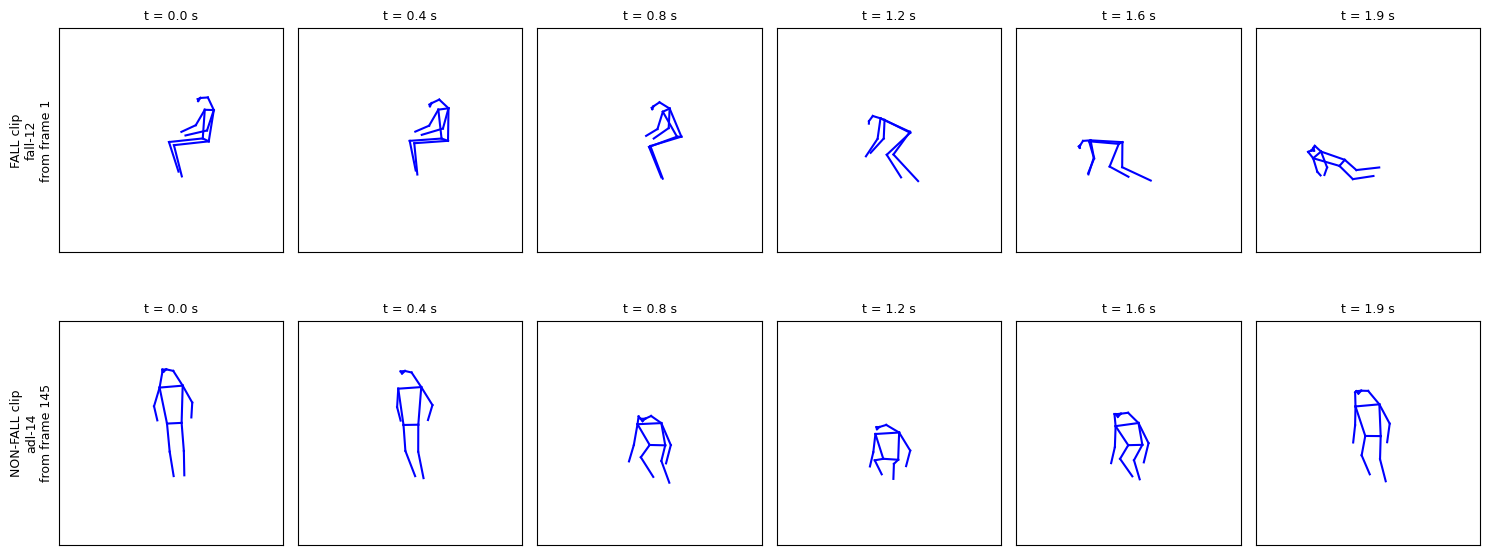

In [ ]:
# ======================================================================
# 9. Build the final skeleton files + 2-second training clips
# ======================================================================
# Uses the section-8 results in memory. After a Colab restart run
# 1, 2, 3, 5, 6, 7, 8 first (8 is fast now: tracking is saved on Drive).
# Builds TRAIN and VALIDATION only. Test is built once, at the very end.
# Writes to NEW folders - the old pose cache is not touched.
# ======================================================================

import json

# Corrections from your review of the pictures:
ACTOR_OVERRIDES = {
    "adl-16": [1, 5, 6, 9],     # ID 7 was a false box at the right edge, not the man
}

MAX_FILL_GAP = 5          # fill holes of up to 5 frames; longer holes stay empty
CLIP_FRAMES = 30          # frames per clip
CLIP_FPS = 15             # 30 frames at 15 FPS = 2 seconds
STRIDE_MS = 200           # start a new clip every 0.2 s
MAX_MISSING_FRAC = 0.3    # skip a clip if > 30% of its frames have no skeleton
FALL_COVER = 0.8          # fall clip = contains >= 80% of the "falling" frames

POSE_V2_ROOT = PROJECT_ROOT / "pose_cache" / "botsort_actor_v1"
DATASET_ROOT = PROJECT_ROOT / "datasets"
DATASET_ROOT.mkdir(parents=True, exist_ok=True)

DATASET_SETTINGS = {
    "pose_model": "yolov8n-pose.pt", "tracker": "botsort+reid (frozen, section 13)",
    "max_fill_gap": MAX_FILL_GAP, "clip_frames": CLIP_FRAMES, "clip_fps": CLIP_FPS,
    "stride_ms": STRIDE_MS, "max_missing_frac": MAX_MISSING_FRAC, "fall_cover": FALL_COVER,
    "joint_ok": JOINT_OK, "normalization": "per clip: centre = mean joint position, "
                                         "scale = median body size; missing frames = 0",
    "channels": "x, y, joint confidence", "joint_order": "COCO-17",
    "labels": "1 = fall, 0 = non-fall, -1 = ambiguous (not used for training)",
}


def actor_sequence(video):
    """Actor skeleton for every frame + short holes filled.
    source: 1 = detected, 2 = filled (interpolated), 0 = missing."""
    b = batch[video]
    ids = ACTOR_OVERRIDES.get(video, b["actor_ids"])
    T = len(b["frame_numbers"])
    xy, kc, _, src = join_actor(b["det"], ids, T)
    found = src > 0
    source = found.astype(np.int8)
    i = 0
    while i < T:
        if found[i]:
            i += 1
            continue
        j = i
        while j + 1 < T and not found[j + 1]:
            j += 1
        if i > 0 and j < T - 1 and (j - i + 1) <= MAX_FILL_GAP:
            a, c = i - 1, j + 1
            w = (np.arange(i, j + 1) - a) / (c - a)
            xy[i:j + 1] = (1 - w)[:, None, None] * xy[a] + w[:, None, None] * xy[c]
            kc[i:j + 1] = (1 - w)[:, None] * kc[a] + w[:, None] * kc[c]
            source[i:j + 1] = 2
        i = j + 1
    xy[source == 0] = 0
    kc[source == 0] = 0
    return ids, xy, kc, source


def timestamps_of(video, fn):
    meta = cam0_metadata[cam0_metadata["sequence_name"].eq(video)].set_index("frame")
    ts = meta["timestamp_ms"].reindex(fn).to_numpy(dtype=float)
    if not np.isfinite(ts).all() or not (np.diff(ts) > 0).all():
        ts = (fn - fn[0]) * (1000 / 30)          # fallback: URFD is 30 FPS
    return ts - ts[0]


def normalize_clip(xy, kc, valid):
    """Centre and scale one clip by the person's own size.
    One centre/scale for the whole clip, so the downward movement of a fall is kept."""
    good = (kc >= JOINT_OK) & valid[:, None]
    centres, sizes = [], []
    for t in range(len(xy)):
        pts = xy[t][good[t]]
        if len(pts) >= 2:
            centres.append(pts.mean(axis=0))
            sizes.append(max(np.ptp(pts[:, 0]), np.ptp(pts[:, 1])))
    if len(sizes) < 3:
        return None
    scale = float(np.median(sizes))
    if scale < 5:                                # pixels - too small to trust
        return None
    out = np.zeros((len(xy), 17, 3), dtype=np.float32)
    out[..., :2] = np.clip((xy - np.mean(centres, axis=0)) / scale, -5, 5)
    out[..., 2] = kc
    out[~valid] = 0
    return out


def make_clips(video, xy, kc, source, ts, posture, category):
    """Cut one video into 2-second clips and label them."""
    step = 1000 / CLIP_FPS
    span = (CLIP_FRAMES - 1) * step
    last_start = ts[-1] - span
    starts = (np.arange(0, last_start + 1e-6, STRIDE_MS) if last_start >= 0
              else np.array([0.0]))              # video shorter than 2 s: one clip, last frame repeated
    falling = np.flatnonzero(posture == 0)
    clips, labels, first_frames, skipped = [], [], [], 0
    for s in starts:
        want = s + step * np.arange(CLIP_FRAMES)
        idx = np.clip(np.searchsorted(ts, want), 0, len(ts) - 1)
        prev = np.clip(idx - 1, 0, len(ts) - 1)
        idx = np.where(np.abs(ts[prev] - want) < np.abs(ts[idx] - want), prev, idx)
        valid = source[idx] > 0
        if (~valid).mean() > MAX_MISSING_FRAC:
            skipped += 1
            continue
        clip = normalize_clip(xy[idx], kc[idx], valid)
        if clip is None:
            skipped += 1
            continue
        if category == "non_fall":
            label = 0
        elif not len(falling):
            label = -1
        else:
            covered = np.mean((falling >= idx[0]) & (falling <= idx[-1]))
            label = 1 if covered >= FALL_COVER else 0 if idx[-1] < falling[0] else -1
        clips.append(clip)
        labels.append(label)
        first_frames.append(int(idx[0]))
    return clips, labels, first_frames, skipped


def build_split(split):
    X, y, clip_video, clip_start, rows = [], [], [], [], []
    out_dir = POSE_V2_ROOT / split
    out_dir.mkdir(parents=True, exist_ok=True)
    for video, b in batch.items():
        if b["split"] != split:
            continue
        fn = b["frame_numbers"]
        ids, xy, kc, source = actor_sequence(video)
        ts = timestamps_of(video, fn)
        image = cv2.imread(str(b["paths"][0]))
        np.savez_compressed(
            out_dir / f"{video}.npz",
            keypoint=xy, keypoint_score=kc, frame_source=source,
            frame_numbers=fn, timestamp_ms=ts, posture_label=b["posture"],
            actor_ids=np.array(ids), img_shape=np.array(image.shape[:2]),
            video=video, split=split, sequence_class=b["category"],
            settings=json.dumps(DATASET_SETTINGS),
        )
        clips, labels, starts, skipped = make_clips(video, xy, kc, source, ts, b["posture"], b["category"])
        X += clips
        y += labels
        clip_video += [video] * len(clips)
        clip_start += [int(fn[s]) for s in starts]
        rows.append({"video": video, "class": b["category"],
                     "detected": int((source == 1).sum()), "filled": int((source == 2).sum()),
                     "missing": int((source == 0).sum()),
                     "fall_clips": labels.count(1), "nonfall_clips": labels.count(0),
                     "unused_clips": labels.count(-1), "skipped_clips": skipped})
    X = np.stack(X) if X else np.zeros((0, CLIP_FRAMES, 17, 3), np.float32)
    return X, np.array(y), np.array(clip_video), np.array(clip_start), pd.DataFrame(rows)


clips_data = {}
for split in ["train", "val"]:
    X, y, vids, starts, table = build_split(split)
    clips_data[split] = {"X": X, "y": y, "video": vids, "start_frame": starts}
    print(f"\n========== {split.upper()} ==========")
    print(table.to_string(index=False))
    print(f"Clips: fall={int((y == 1).sum())}, non-fall={int((y == 0).sum())}, "
          f"unused={int((y == -1).sum())} | clip shape {X.shape[1:]}")
    no_fall = table[(table["class"] == "fall") & (table["fall_clips"] == 0)]["video"].tolist()
    if no_fall:
        print("WARNING - fall videos with no usable fall clip:", no_fall)

dataset_file = DATASET_ROOT / "urfd_clips_trainval_v1.npz"
np.savez_compressed(
    dataset_file,
    **{f"{k}_{s}": v for s, d in clips_data.items() for k, v in d.items()},
    settings=json.dumps(DATASET_SETTINGS),
)
print("\nSaved dataset:", dataset_file)
print("Saved skeleton files:", POSE_V2_ROOT)

# ---------------- picture: one fall clip and one non-fall clip ----------------
d = clips_data["train"]
examples = []
for wanted, name in [(1, "FALL clip"), (0, "NON-FALL clip")]:
    pick = [k for k in range(len(d["y"])) if d["y"][k] == wanted
            and (wanted == 1 or d["video"][k].startswith("adl"))]
    if pick:
        examples.append((name, pick[len(pick) // 2]))

steps = [0, 6, 12, 18, 24, 29]
fig, axes = plt.subplots(len(examples), len(steps), figsize=(15, 3.2 * len(examples)), squeeze=False)
for row, (name, k) in enumerate(examples):
    clip = d["X"][k]
    for col, t in enumerate(steps):
        ax = axes[row, col]
        for p, q in COCO_EDGES:
            if clip[t, p, 2] >= JOINT_OK and clip[t, q, 2] >= JOINT_OK:
                ax.plot([clip[t, p, 0], clip[t, q, 0]], [-clip[t, p, 1], -clip[t, q, 1]], "b-")
        ax.set_xlim(-1.5, 1.5)
        ax.set_ylim(-1.5, 1.5)
        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(f"t = {t / CLIP_FPS:.1f} s", fontsize=9)
    axes[row, 0].set_ylabel(f"{name}\n{d['video'][k]}\nfrom frame {d['start_frame'][k]}", fontsize=9)
plt.tight_layout()
plt.show()

# **10. Train ST-GCN++ for fall / non-fall**
Uses train to learn and validation to pick the best epoch. Saves `checkpoints/stgcnpp_fall_binary_v1.pth`. The test set is not used.
**Locked:** it stops if a trained model already exists. Set `RETRAIN = True` only when you really want to train again (this replaces the saved model, and the laptop files must be exported again with section 11).

Train clips: 452 (fall 77, non-fall 375)
Val clips:   119 (fall 17, non-fall 102)
Pretrained NTU60 body loaded; new 2-class output: ['cls_head.fc.weight', 'cls_head.fc.bias']
epoch   1 | train loss 0.335 | val loss 0.073 | val F1 0.87 | val recall 1.00 | val false alarms 0.05
epoch  10 | train loss 0.021 | val loss 0.056 | val F1 0.91 | val recall 0.94 | val false alarms 0.02
epoch  20 | train loss 0.002 | val loss 0.008 | val F1 1.00 | val recall 1.00 | val false alarms 0.00
epoch  30 | train loss 0.006 | val loss 0.025 | val F1 0.97 | val recall 1.00 | val false alarms 0.01
epoch  40 | train loss 0.008 | val loss 0.012 | val F1 1.00 | val recall 1.00 | val false alarms 0.00
epoch  50 | train loss 0.001 | val loss 0.014 | val F1 1.00 | val recall 1.00 | val false alarms 0.00
epoch  60 | train loss 0.003 | val loss 0.006 | val F1 1.00 | val recall 1.00 | val false alarms 0.00

Training time: 88 s
Best epoch (highest validation F1, then lowest val loss): 58

Validation results per thres

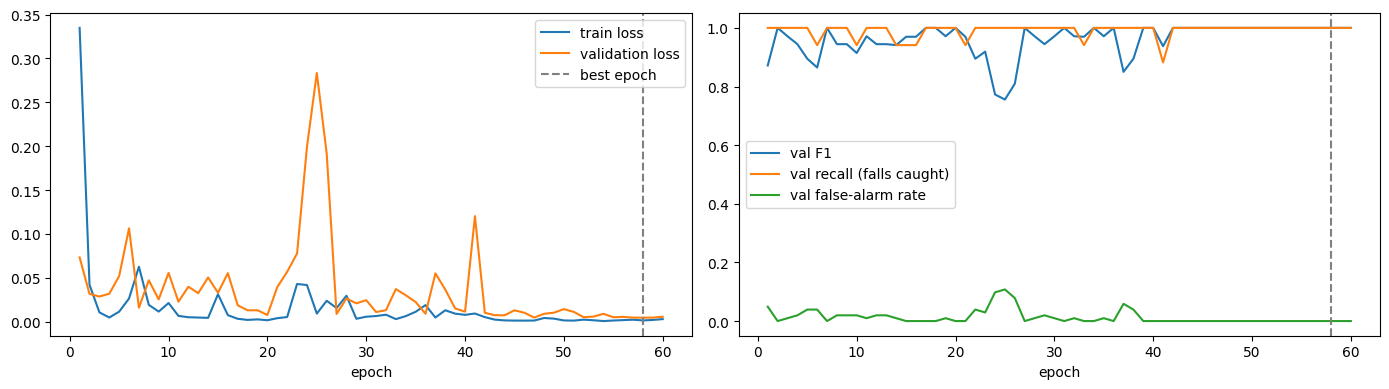

In [ ]:
# ======================================================================
# 10. Train ST-GCN++ for fall / non-fall
# ======================================================================
# Needs sections 1, 2, 3 and 4 (packages, Drive, pretrained checkpoint).
# Reads the clip file from section 9 (saved on Drive).
# Uses TRAIN to learn and VALIDATION to pick the best version.
# The test set is NOT used here.
# ======================================================================

import copy
import json
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from mmengine.config import Config
from mmengine.registry import init_default_scope
from mmaction.registry import MODELS

SEED = 42
EPOCHS = 60
BATCH_SIZE = 32
LR_BACKBONE = 2e-4        # small steps for the pretrained part
LR_HEAD = 2e-3            # bigger steps for the new 2-class output
WEIGHT_DECAY = 1e-4
MODEL_FILE = CHECKPOINT_ROOT / "stgcnpp_fall_binary_v1.pth"
RETRAIN = False            # True = train again and REPLACE the saved model on Drive
assert RETRAIN or not MODEL_FILE.exists(), (
    "A trained model is already saved on Drive. Set RETRAIN = True only if you really want to train again.")
DATASET_FILE = PROJECT_ROOT / "datasets" / "urfd_clips_trainval_v1.npz"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ---------------- 1. Load the clips ----------------
with np.load(DATASET_FILE, allow_pickle=False) as data:
    X_train, y_train = data["X_train"], data["y_train"]
    X_val, y_val, video_val = data["X_val"], data["y_val"], data["video_val"]
    dataset_settings = json.loads(str(data["settings"]))

train_keep = y_train >= 0                 # -1 = ambiguous clips, not used for training
X_train, y_train = X_train[train_keep], y_train[train_keep]
val_keep = y_val >= 0
print(f"Train clips: {len(y_train)} (fall {int((y_train == 1).sum())}, non-fall {int((y_train == 0).sum())})")
print(f"Val clips:   {int(val_keep.sum())} (fall {int((y_val == 1).sum())}, non-fall {int((y_val == 0).sum())})")

# ---------------- 2. Build ST-GCN++ with a 2-class output ----------------
cfg = Config.fromfile(str(config_path))
cfg.model.cls_head.num_classes = 2
init_default_scope("mmaction")
model = MODELS.build(cfg.model)

pretrained = torch.hub.load_state_dict_from_url(
    checkpoint_url, model_dir=str(CHECKPOINT_ROOT), map_location="cpu", weights_only=False
)["state_dict"]
pretrained = {k: v for k, v in pretrained.items() if not k.startswith("cls_head.")}
missing, unexpected = model.load_state_dict(pretrained, strict=False)
assert not unexpected, unexpected
assert all(k.startswith("cls_head.") for k in missing), missing
print("Pretrained NTU60 body loaded; new 2-class output:", missing)
model = model.to(DEVICE)


def forward(batch_x):
    """batch_x: (N, 30, 17, 3) -> logits (N, 2). One person per clip (M = 1)."""
    x = batch_x.unsqueeze(1)                      # (N, 1, T, V, C)
    return model.cls_head(model.backbone(x))


# ---------------- 3. Training helpers ----------------
FLIP = [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15]   # COCO left <-> right


def augment(x):
    """Small random changes so the model does not memorise exact clips."""
    x = x.clone()
    flip = torch.rand(len(x), device=x.device) < 0.5   # mirror left <-> right
    x[flip] = x[flip][:, :, FLIP]
    x[flip, ..., 0] *= -1
    present = (x[..., 2:3] > 0).float()           # keep missing joints at 0
    scale = torch.empty(len(x), 1, 1, 1, device=x.device).uniform_(0.9, 1.1)
    shift = torch.empty(len(x), 1, 1, 2, device=x.device).uniform_(-0.1, 0.1)
    x[..., :2] = (x[..., :2] * scale + shift) * present
    return x


@torch.no_grad()
def predict(X):
    model.eval()
    probs = []
    for i in range(0, len(X), 128):
        xb = torch.as_tensor(X[i:i + 128], device=DEVICE)
        probs.append(torch.softmax(forward(xb), dim=1)[:, 1].cpu().numpy())
    return np.concatenate(probs) if probs else np.zeros(0)


def scores(y_true, prob, threshold):
    pred = (prob >= threshold).astype(int)
    tp = int(((pred == 1) & (y_true == 1)).sum())
    tn = int(((pred == 0) & (y_true == 0)).sum())
    fp = int(((pred == 1) & (y_true == 0)).sum())
    fn = int(((pred == 0) & (y_true == 1)).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {
        "accuracy": (tp + tn) / max(len(y_true), 1),
        "precision": precision, "recall": recall,
        "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        "false_alarm_rate": fp / (fp + tn) if fp + tn else 0.0,
        "tp": tp, "fp": fp, "tn": tn, "fn": fn,
    }


counts = np.bincount(y_train, minlength=2)
class_weight = torch.tensor(len(y_train) / (2 * counts), dtype=torch.float32, device=DEVICE)
loss_fn = nn.CrossEntropyLoss(weight=class_weight)       # fall clips count more (they are rarer)
optimizer = torch.optim.AdamW([
    {"params": model.backbone.parameters(), "lr": LR_BACKBONE},
    {"params": model.cls_head.parameters(), "lr": LR_HEAD},
], weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

Xt = torch.as_tensor(X_train, device=DEVICE)
yt = torch.as_tensor(y_train, dtype=torch.long, device=DEVICE)
Xv_t = torch.as_tensor(X_val[val_keep], device=DEVICE)
yv_t = torch.as_tensor(y_val[val_keep], dtype=torch.long, device=DEVICE)

# ---------------- 4. Train ----------------
history, best = [], None
start = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    order = torch.randperm(len(Xt), device=DEVICE)
    total = 0.0
    for i in range(0, len(order), BATCH_SIZE):
        idx = order[i:i + BATCH_SIZE]
        if len(idx) < 2:
            continue
        loss = loss_fn(forward(augment(Xt[idx])), yt[idx])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * len(idx)
    scheduler.step()

    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(forward(Xv_t), yv_t).item()
    val = scores(y_val[val_keep], predict(X_val[val_keep]), 0.5)
    history.append({"epoch": epoch, "train_loss": total / len(Xt), "val_loss": val_loss, **val})

    if best is None or (val["f1"], -val_loss) > (best["f1"], -best["val_loss"]):
        best = {"epoch": epoch, "f1": val["f1"], "val_loss": val_loss,
                "state": copy.deepcopy(model.state_dict())}
    if epoch % 10 == 0 or epoch == 1:
        print(f"epoch {epoch:3d} | train loss {total / len(Xt):.3f} | val loss {val_loss:.3f} | "
              f"val F1 {val['f1']:.2f} | val recall {val['recall']:.2f} | "
              f"val false alarms {val['false_alarm_rate']:.2f}")

print(f"\nTraining time: {time.time() - start:.0f} s")
print(f"Best epoch (highest validation F1, then lowest val loss): {best['epoch']}")
model.load_state_dict(best["state"])

# ---------------- 5. Choose the alarm threshold on VALIDATION ----------------
val_prob_all = predict(X_val)                     # every val clip, including unused ones
val_prob = val_prob_all[val_keep]
candidates = np.round(np.arange(0.30, 0.91, 0.05), 2)
table = pd.DataFrame([{"threshold": t, **scores(y_val[val_keep], val_prob, t)} for t in candidates])
best_row = table.sort_values(["f1", "false_alarm_rate", "threshold"],
                             ascending=[False, True, False]).iloc[0]
THRESHOLD = float(best_row["threshold"])
print("\nValidation results per threshold (clip level):")
print(table[["threshold", "accuracy", "precision", "recall", "f1", "false_alarm_rate"]]
      .round(3).to_string(index=False))
print(f"\nChosen threshold: {THRESHOLD}")

# Video level = what the system does: alarm if ANY clip in the video is above the threshold.
video_rows = []
for video in sorted(set(video_val)):
    k = video_val == video
    video_rows.append({"video": video, "true": "fall" if video.startswith("fall") else "non-fall",
                       "max_fall_prob": round(float(val_prob_all[k].max()), 3),
                       "alarm": bool(val_prob_all[k].max() >= THRESHOLD)})
video_table = pd.DataFrame(video_rows)
print("\nValidation videos (alarm if any 2-second clip is above the threshold):")
print(video_table.to_string(index=False))

# ---------------- 6. Save the model ----------------
torch.save({
    "state_dict": best["state"], "threshold": THRESHOLD, "best_epoch": best["epoch"],
    "num_classes": 2, "classes": ["non_fall", "fall"],
    "config": config_path.name, "dataset_settings": dataset_settings,
    "train_settings": {"seed": SEED, "epochs": EPOCHS, "batch_size": BATCH_SIZE,
                       "lr_backbone": LR_BACKBONE, "lr_head": LR_HEAD,
                       "weight_decay": WEIGHT_DECAY, "class_weight": class_weight.tolist()},
    "val_clip_scores": scores(y_val[val_keep], val_prob, THRESHOLD),
}, MODEL_FILE)
print("\nSaved model:", MODEL_FILE)

# ---------------- 7. Training curves ----------------
h = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(h["epoch"], h["train_loss"], label="train loss")
axes[0].plot(h["epoch"], h["val_loss"], label="validation loss")
axes[0].axvline(best["epoch"], color="gray", linestyle="--", label="best epoch")
axes[0].set_xlabel("epoch")
axes[0].legend()
axes[1].plot(h["epoch"], h["f1"], label="val F1")
axes[1].plot(h["epoch"], h["recall"], label="val recall (falls caught)")
axes[1].plot(h["epoch"], h["false_alarm_rate"], label="val false-alarm rate")
axes[1].axvline(best["epoch"], color="gray", linestyle="--")
axes[1].set_ylim(-0.05, 1.05)
axes[1].set_xlabel("epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

# **10b. Cross-validation: is the result stable? 2-second or 3-second clips?**

**What it does**
- Uses only the **47 train + validation videos**. The 10 test videos are **not touched**.
- Splits the 47 videos into **5 groups (folds)**, each with about 5 falls and 4–5 normal videos.
- Trains ST-GCN++ **5 times**. Each time one group is left out and checked afterwards, so every video is checked once by a model that never saw it.
- Does this for **two clip lengths**:
  - **2 s** = 30 frames at 15 FPS (what we use now)
  - **3 s** = 30 frames at 10 FPS (the team's sequence length)
- Same training recipe as section 10 (NTU60 starting weights, threshold 0.5), but with a fixed 50 rounds and **no picking of the best round using the left-out group**, so the check is fair.

**Why**
- Section 10 was checked on only 8 videos, and the same videos were used to pick the best round, so its numbers are too optimistic. This gives realistic numbers for all 47 videos and shows whether the result is stable.
- It decides the clip length (2 s or 3 s) with data instead of guessing.
- It saves the exact groups and clips so the LSTM can be checked on the **same videos** for a fair comparison.

**Output**
- Results for every fold.
- A summary table: accuracy, precision, recall, F1 and false-alarm rate (average ± spread over the 5 folds), plus falls caught and normal videos with a false alarm (out of all 47 videos).
- The list of videos the model got wrong.

**Files saved (new files, nothing is overwritten)**
- `results/stgcnpp_cv_folds_v1.csv`, `results/stgcnpp_cv_summary_v1.json`
- `datasets/cv_folds_v1.json`, `datasets/cv_clips_2s_15fps_v1.npz`, `datasets/cv_clips_3s_10fps_v1.npz`

**Does NOT change** the saved model `checkpoints/stgcnpp_fall_binary_v1.pth`.

**Run first:** sections 1–9 (skip 7b and 10). **Time:** about 15–20 minutes on the T4. Keep the tab open.

In [ ]:
# ======================================================================
# 10b. Cross-validation: is the result stable?  2-second or 3-second clips?
# ======================================================================
# Uses ONLY the 47 train + validation videos. The test set is NOT touched.
# The 47 videos are split into 5 groups ("folds"). The model is trained 5
# times; each time one group is held out and checked. So every video is
# checked once, by a model that never saw it - much more reliable than
# 8 validation videos.
# This is done for two clip lengths:
#   2s_15fps = 30 frames at 15 FPS (what we use now)
#   3s_10fps = 30 frames at 10 FPS (the team's 3-second sequences)
# Needs sections 1-9 in this session (section 8 is fast now). ~15-20 min on T4.
# Saves the folds + clips to Drive so the LSTM can be checked on the SAME folds.
# Does not overwrite the trained model or any earlier file.
# ======================================================================

import copy
import json
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from mmengine.config import Config
from mmengine.registry import init_default_scope
from mmaction.registry import MODELS

N_FOLDS = 5
CV_EPOCHS = 50            # fixed number of rounds - we never pick the epoch on the held-out fold
CV_THRESHOLD = 0.5
WINDOWS = {"2s_15fps": (30, 15), "3s_10fps": (30, 10)}
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
RESULTS_ROOT = PROJECT_ROOT / "results"
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

# ---------------- 1. Folds by video (same folds for every clip length and every model) ----------------
cv_videos = sorted(v for v, b in batch.items() if b["split"] in ("train", "val"))
rng = random.Random(SEED)
fold_of = {}
for cls in ["fall", "non_fall"]:                       # each fold gets ~5 falls and ~4-5 normal videos
    group = [v for v in cv_videos if batch[v]["category"] == cls]
    rng.shuffle(group)
    for k, v in enumerate(group):
        fold_of[v] = k % N_FOLDS
(DATASET_ROOT / "cv_folds_v1.json").write_text(json.dumps(fold_of, indent=1))
for k in range(N_FOLDS):
    members = [v for v in cv_videos if fold_of[v] == k]
    print(f"Fold {k + 1}: {sum(batch[v]['category'] == 'fall' for v in members)} falls, "
          f"{sum(batch[v]['category'] != 'fall' for v in members)} normal -> {', '.join(members)}")


# ---------------- 2. Clips for one clip length (same rules as section 9) ----------------
def clips_for_window(frames, fps):
    global CLIP_FRAMES, CLIP_FPS
    original = (CLIP_FRAMES, CLIP_FPS)
    CLIP_FRAMES, CLIP_FPS = frames, fps
    try:
        X, y, vid = [], [], []
        for v in cv_videos:
            b = batch[v]
            _, xy, kc, source = actor_sequence(v)
            ts = timestamps_of(v, b["frame_numbers"])
            clips, labels, _, _ = make_clips(v, xy, kc, source, ts, b["posture"], b["category"])
            X += clips
            y += labels
            vid += [v] * len(clips)
    finally:
        CLIP_FRAMES, CLIP_FPS = original           # section 9 settings stay unchanged
    return np.stack(X).astype(np.float32), np.array(y), np.array(vid)


# ---------------- 3. Training (same recipe as section 10, fixed number of rounds) ----------------
cfg = Config.fromfile(str(config_path))
cfg.model.cls_head.num_classes = 2
init_default_scope("mmaction")
pretrained = torch.hub.load_state_dict_from_url(
    checkpoint_url, model_dir=str(CHECKPOINT_ROOT), map_location="cpu", weights_only=False
)["state_dict"]
pretrained = {k: v for k, v in pretrained.items() if not k.startswith("cls_head.")}
FLIP = [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15]


def augment(x):
    x = x.clone()
    flip = torch.rand(len(x), device=x.device) < 0.5
    x[flip] = x[flip][:, :, FLIP]
    x[flip, ..., 0] *= -1
    present = (x[..., 2:3] > 0).float()
    scale = torch.empty(len(x), 1, 1, 1, device=x.device).uniform_(0.9, 1.1)
    shift = torch.empty(len(x), 1, 1, 2, device=x.device).uniform_(-0.1, 0.1)
    x[..., :2] = (x[..., :2] * scale + shift) * present
    return x


def train_model(X_tr, y_tr, seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    model = MODELS.build(cfg.model)
    model.load_state_dict(pretrained, strict=False)
    model = model.to(DEVICE)
    counts = np.bincount(y_tr, minlength=2)
    loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(len(y_tr) / (2 * counts), dtype=torch.float32, device=DEVICE))
    optimizer = torch.optim.AdamW([
        {"params": model.backbone.parameters(), "lr": 2e-4},
        {"params": model.cls_head.parameters(), "lr": 2e-3},
    ], weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CV_EPOCHS)
    Xt = torch.as_tensor(X_tr, device=DEVICE)
    yt = torch.as_tensor(y_tr, dtype=torch.long, device=DEVICE)
    for _ in range(CV_EPOCHS):
        model.train()
        order = torch.randperm(len(Xt), device=DEVICE)
        for i in range(0, len(order), 32):
            idx = order[i:i + 32]
            if len(idx) < 2:
                continue
            loss = loss_fn(model.cls_head(model.backbone(augment(Xt[idx]).unsqueeze(1))), yt[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        scheduler.step()
    return model.eval()


@torch.no_grad()
def predict_probs(model, X):
    out = []
    for i in range(0, len(X), 128):
        xb = torch.as_tensor(X[i:i + 128], device=DEVICE).unsqueeze(1)
        out.append(torch.softmax(model.cls_head(model.backbone(xb)), 1)[:, 1].cpu().numpy())
    return np.concatenate(out)


def clip_scores(y_true, prob, threshold):
    pred = (prob >= threshold).astype(int)
    tp = int(((pred == 1) & (y_true == 1)).sum()); tn = int(((pred == 0) & (y_true == 0)).sum())
    fp = int(((pred == 1) & (y_true == 0)).sum()); fn = int(((pred == 0) & (y_true == 1)).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {"accuracy": (tp + tn) / max(len(y_true), 1), "precision": precision, "recall": recall,
            "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
            "false_alarm_rate": fp / (fp + tn) if fp + tn else 0.0,
            "tp": tp, "fp": fp, "tn": tn, "fn": fn}


def video_max(probs, vid, v):
    p = probs[vid == v]
    return float(p.max()) if len(p) else 0.0          # no usable clip -> no alarm (a fall counts as missed)


# ---------------- 4. Run: 2 clip lengths x 5 folds ----------------
rows, pooled = [], {}
start_all = time.time()
for tag, (frames, fps) in WINDOWS.items():
    X, y, vid = clips_for_window(frames, fps)
    np.savez_compressed(DATASET_ROOT / f"cv_clips_{tag}_v1.npz", X=X, y=y, video=vid)
    fold = np.array([fold_of[v] for v in vid])
    probs = np.full(len(y), np.nan)
    print(f"\n=== {tag}: {len(y)} clips (fall {int((y == 1).sum())}, non-fall {int((y == 0).sum())}, "
          f"unused {int((y == -1).sum())}) ===")
    for k in range(N_FOLDS):
        t0 = time.time()
        train = (fold != k) & (y >= 0)
        held = fold == k
        model = train_model(X[train], y[train], SEED + k)
        probs[held] = predict_probs(model, X[held])
        labelled = held & (y >= 0)
        s = clip_scores(y[labelled], probs[labelled], CV_THRESHOLD)
        held_videos = [v for v in cv_videos if fold_of[v] == k]       # ALL videos of the fold
        fall_v = [v for v in held_videos if batch[v]["category"] == "fall"]
        norm_v = [v for v in held_videos if batch[v]["category"] != "fall"]
        caught = sum(video_max(probs, vid, v) >= CV_THRESHOLD for v in fall_v)
        alarmed = sum(video_max(probs, vid, v) >= CV_THRESHOLD for v in norm_v)
        missed = [v for v in fall_v if video_max(probs, vid, v) < CV_THRESHOLD]
        false_alarm_videos = [v for v in norm_v if video_max(probs, vid, v) >= CV_THRESHOLD]
        rows.append({"clips": tag, "fold": k + 1, **{m: round(s[m], 3) for m in
                     ["accuracy", "precision", "recall", "f1", "false_alarm_rate"]},
                     "falls_caught": f"{caught}/{len(fall_v)}", "normal_alarmed": f"{alarmed}/{len(norm_v)}",
                     "missed_falls": ", ".join(missed), "false_alarm_videos": ", ".join(false_alarm_videos)})
        print(f"  fold {k + 1}: F1 {s['f1']:.2f} | recall {s['recall']:.2f} | false alarms {s['false_alarm_rate']:.2f} | "
              f"falls caught {caught}/{len(fall_v)} | normal videos alarmed {alarmed}/{len(norm_v)} "
              f"| {time.time() - t0:.0f} s")
        del model
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
    keep = y >= 0
    all_fall = [v for v in cv_videos if batch[v]["category"] == "fall"]
    all_norm = [v for v in cv_videos if batch[v]["category"] != "fall"]
    pooled[tag] = {**clip_scores(y[keep], probs[keep], CV_THRESHOLD),
                   "falls_caught": int(sum(video_max(probs, vid, v) >= CV_THRESHOLD for v in all_fall)),
                   "falls_total": len(all_fall),
                   "normal_alarmed": int(sum(video_max(probs, vid, v) >= CV_THRESHOLD for v in all_norm)),
                   "normal_total": len(all_norm),
                   "videos_without_clip": [v for v in cv_videos if not (vid == v).any()]}

# ---------------- 5. Summary ----------------
table = pd.DataFrame(rows)
table.to_csv(RESULTS_ROOT / "stgcnpp_cv_folds_v1.csv", index=False)
(RESULTS_ROOT / "stgcnpp_cv_summary_v1.json").write_text(json.dumps(
    {"folds": N_FOLDS, "epochs": CV_EPOCHS, "threshold": CV_THRESHOLD, "pooled": pooled}, indent=2))

print(f"\nTotal time: {(time.time() - start_all) / 60:.1f} min")
print(f"\n========== CROSS-VALIDATION SUMMARY ({len(cv_videos)} train+val videos, threshold {CV_THRESHOLD}) ==========")
summary = []
for tag in WINDOWS:
    t = table[table["clips"] == tag]
    p = pooled[tag]
    summary.append({
        "clips": tag,
        "accuracy": f"{t['accuracy'].mean():.3f} ± {t['accuracy'].std():.3f}",
        "precision": f"{t['precision'].mean():.3f} ± {t['precision'].std():.3f}",
        "recall": f"{t['recall'].mean():.3f} ± {t['recall'].std():.3f}",
        "F1": f"{t['f1'].mean():.3f} ± {t['f1'].std():.3f}",
        "false_alarm_rate": f"{t['false_alarm_rate'].mean():.3f} ± {t['false_alarm_rate'].std():.3f}",
        "falls_caught (videos)": f"{p['falls_caught']}/{p['falls_total']}",
        "normal_videos_alarmed": f"{p['normal_alarmed']}/{p['normal_total']}",
    })
print(pd.DataFrame(summary).to_string(index=False))
print(f"(clip-level numbers = mean ± spread over the {N_FOLDS} folds; video counts = all {len(cv_videos)} videos)")

mistakes = table[(table["missed_falls"] != "") | (table["false_alarm_videos"] != "")]
if len(mistakes):
    print("\nVideos the model got wrong (useful to look at):")
    print(mistakes[["clips", "fold", "missed_falls", "false_alarm_videos"]].to_string(index=False))
print("\nSaved:", RESULTS_ROOT / "stgcnpp_cv_folds_v1.csv")
print("Saved:", RESULTS_ROOT / "stgcnpp_cv_summary_v1.json")
print("Saved folds + clips for the LSTM:", DATASET_ROOT / "cv_folds_v1.json", "and cv_clips_*_v1.npz")

Fold 1: 5 falls, 5 normal -> adl-03, adl-13, adl-27, adl-31, adl-34, fall-11, fall-12, fall-17, fall-19, fall-22
Fold 2: 5 falls, 5 normal -> adl-12, adl-16, adl-26, adl-32, adl-35, fall-03, fall-08, fall-13, fall-18, fall-23
Fold 3: 5 falls, 4 normal -> adl-14, adl-19, adl-24, adl-33, fall-01, fall-02, fall-14, fall-15, fall-29
Fold 4: 5 falls, 4 normal -> adl-06, adl-08, adl-09, adl-18, fall-04, fall-07, fall-20, fall-21, fall-25
Fold 5: 5 falls, 4 normal -> adl-01, adl-04, adl-07, adl-28, fall-24, fall-26, fall-27, fall-28, fall-30

=== 2s_15fps: 620 clips (fall 94, non-fall 477, unused 49) ===
  fold 1: F1 1.00 | recall 1.00 | false alarms 0.00 | falls caught 5/5 | normal videos alarmed 0/5 | 51 s
  fold 2: F1 0.92 | recall 0.86 | false alarms 0.00 | falls caught 5/5 | normal videos alarmed 0/5 | 49 s
  fold 3: F1 0.86 | recall 1.00 | false alarms 0.09 | falls caught 5/5 | normal videos alarmed 3/4 | 53 s
  fold 4: F1 0.94 | recall 0.89 | false alarms 0.00 | falls caught 5/5 | norm

# **10c. See how the model judged a video**
Makes a video with the person's **box + skeleton**, URFD's label, the model's **fall probability** frame by frame, a **FALL DETECTED** banner at ≥ 0.7, and a graph at the bottom (blue = probability, red band = URFD "falling" frames). Also prints every 2-second clip of the video with its label and probability.
Saved to `results/explained_videos/`. Use **validation** videos for an honest view; test videos are blocked. Changes no other files.

In [ ]:
# ======================================================================
# 10c. SEE how the model judged a video (box + skeleton + fall probability)
# ======================================================================
# Makes a video for each name in VIDEOS:
#   - the actor's box and skeleton on every frame (orange = filled gap, no box = missing)
#   - URFD's own label for that frame (not lying / falling / lying)
#   - the fall probability from the trained model, frame by frame
#   - a red "FALL DETECTED" banner when the probability is >= THRESHOLD (0.7)
#   - a graph at the bottom: probability over time, red band = URFD "falling" frames
# Saved to Drive: results/explained_videos/<video>.mp4 and shown here.
# Needs sections 1-9 in this session. Does not change any file except the new videos.
# Use VALIDATION videos for an honest view (the model never trained on them):
#   fall-02, fall-15, fall-25, fall-29, adl-03, adl-13, adl-18, adl-33
# Train videos will look perfect, because the model learned from them.
# Test videos are blocked.
# ======================================================================

import base64
import subprocess

import torch
from IPython.display import HTML, display
from mmengine.config import Config
from mmengine.registry import init_default_scope
from mmaction.registry import MODELS

VIDEOS = ["fall-02", "adl-13"]
PLAYBACK_FPS = 15                  # URFD is 30 FPS -> 15 plays at half speed (easier to follow)
THRESHOLD = 0.7
OUT_ROOT = PROJECT_ROOT / "results" / "explained_videos"
OUT_ROOT.mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------- the trained model ----------------
saved = torch.load(CHECKPOINT_ROOT / "stgcnpp_fall_binary_v1.pth", map_location="cpu", weights_only=False)
cfg = Config.fromfile(str(config_path))
cfg.model.cls_head.num_classes = 2
init_default_scope("mmaction")
explain_model = MODELS.build(cfg.model)
explain_model.load_state_dict(saved["state_dict"], strict=True)
explain_model = explain_model.to(DEVICE).eval()


@torch.no_grad()
def clip_probs(clips):
    x = torch.as_tensor(np.stack(clips), device=DEVICE).unsqueeze(1)
    return torch.softmax(explain_model.cls_head(explain_model.backbone(x)), 1)[:, 1].cpu().numpy()


LABEL_TEXT = {-1.0: "not lying", 0.0: "FALLING", 1.0: "lying"}
CLIP_TEXT = {1: "fall", 0: "non-fall", -1: "unused"}


def explain_video(video):
    b = batch[video]
    assert b["split"] != "test", "Test videos are only used once, in section 12."
    fn, paths, posture = b["frame_numbers"], b["paths"], b["posture"]
    T = len(fn)
    ids, xy, kc, source = actor_sequence(video)                    # same skeleton as training
    _, _, boxes, _ = join_actor(b["det"], ids, T)                  # YOLO box of the actor
    ts = timestamps_of(video, fn)
    clips, labels, starts, skipped = make_clips(video, xy, kc, source, ts, posture, b["category"])
    span = (CLIP_FRAMES - 1) * 1000 / CLIP_FPS
    probs = clip_probs(clips) if clips else np.zeros(0)
    ends = [min(int(np.searchsorted(ts, ts[s] + span - 1)), T - 1) for s in starts]   # short video: ends at last frame

    # The 2-second clips of this video
    print(f"\n=== {video} ({b['split']}, {b['category']}) - {T} frames, {len(clips)} clips "
          f"(each about {CLIP_FRAMES / CLIP_FPS:.0f} s long, a new one every {STRIDE_MS / 1000:.1f} s), {skipped} skipped ===")
    for k, (s, e, lab, p) in enumerate(zip(starts, ends, labels, probs)):
        print(f"  clip {k + 1:2d}: {ts[s] / 1000:4.1f}-{ts[e] / 1000:4.1f} s (frames {fn[s]}-{fn[e]}) | "
              f"label {CLIP_TEXT[lab]:8s} | fall probability {p:.2f}{'  <- ALARM' if p >= THRESHOLD else ''}")

    # Probability shown at each frame = the newest clip that has ended by then (like live)
    frame_prob = np.full(T, np.nan)
    for e, p in sorted(zip(ends, probs)):
        frame_prob[e:] = p

    # Bottom graph (drawn once, cursor added per frame)
    W, H, G = 640, 480, 130
    graph = np.full((G, W, 3), 255, np.uint8)
    xpix = lambda i: int(10 + (W - 20) * i / max(T - 1, 1))
    ypix = lambda p: int(G - 20 - (G - 35) * p)
    for i in np.flatnonzero(posture == 0):
        cv2.line(graph, (xpix(i), 15), (xpix(i), G - 20), (200, 200, 255), 2)
    cv2.line(graph, (10, ypix(THRESHOLD)), (W - 10, ypix(THRESHOLD)), (150, 150, 150), 1)
    pts = [(xpix(i), ypix(frame_prob[i])) for i in range(T) if np.isfinite(frame_prob[i])]
    for a, c in zip(pts[:-1], pts[1:]):
        cv2.line(graph, a, c, (200, 0, 0), 2)
    cv2.putText(graph, f"fall probability (blue) | threshold {THRESHOLD} (grey) | URFD 'falling' frames (red band)",
                (10, 12), cv2.FONT_HERSHEY_SIMPLEX, 0.38, (0, 0, 0), 1)

    tmp = Path(f"/content/{video}_raw.mp4")
    writer = cv2.VideoWriter(str(tmp), cv2.VideoWriter_fourcc(*"mp4v"), PLAYBACK_FPS, (W, H + G))
    for i in range(T):
        frame = cv2.resize(cv2.imread(str(paths[i])), (W, H))
        p = frame_prob[i]
        alarm = np.isfinite(p) and p >= THRESHOLD
        if source[i] > 0:
            color = (0, 0, 255) if alarm else (0, 200, 0)
            joint_color = (0, 165, 255) if source[i] == 2 else (0, 255, 255)
            for a, c in COCO_EDGES:
                if kc[i, a] >= JOINT_OK and kc[i, c] >= JOINT_OK:
                    cv2.line(frame, (int(xy[i, a, 0]), int(xy[i, a, 1])), (int(xy[i, c, 0]), int(xy[i, c, 1])), joint_color, 2)
            for (x, y_), c in zip(xy[i], kc[i]):
                if c >= JOINT_OK:
                    cv2.circle(frame, (int(x), int(y_)), 3, (0, 0, 255), -1)
            if np.isfinite(boxes[i]).all():
                x1, y1, x2, y2 = (int(v) for v in boxes[i])
                cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
        if alarm:
            cv2.rectangle(frame, (0, 0), (W, 40), (0, 0, 255), -1)
            cv2.putText(frame, "FALL DETECTED", (12, 29), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2)
        status = {1: "skeleton: detected", 2: "skeleton: FILLED (short gap)", 0: "skeleton: MISSING"}[int(source[i])]
        lines = [f"{video}  frame {fn[i]}  t={ts[i] / 1000:.1f}s",
                 f"URFD label: {LABEL_TEXT.get(posture[i], 'no label')}",
                 status,
                 "fall probability: " + ("waiting for 2 s of history" if not np.isfinite(p) else f"{p:.2f}")]
        band = frame[45:132, 0:340]
        frame[45:132, 0:340] = (band * 0.35).astype(np.uint8)          # dark band behind the text
        for k, text in enumerate(lines):
            cv2.putText(frame, text, (10, 62 + 20 * k), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
        panel = graph.copy()
        cv2.line(panel, (xpix(i), 15), (xpix(i), G - 20), (0, 0, 0), 1)
        writer.write(np.vstack([frame, panel]))
    writer.release()

    out = OUT_ROOT / f"{video}_explained.mp4"
    done = subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(tmp), "-vcodec", "libx264",
                           "-pix_fmt", "yuv420p", str(out)]).returncode == 0
    if not done:                                   # no ffmpeg: keep the basic mp4 file
        out.write_bytes(tmp.read_bytes())
    print("Saved:", out)
    data = base64.b64encode(out.read_bytes()).decode()
    display(HTML(f'<p><b>{video}</b></p><video width="640" controls src="data:video/mp4;base64,{data}"></video>'))


for name in VIDEOS:
    explain_video(name)


# **10d. Compare my ST-GCN++ with the LSTM (fair test)**
Trains ST-GCN++, the LSTM from the team's progress file, and the LSTM + augmentation on the **same clips, labels and 5 folds** as 10b, then prints one table (F1, recall, false alarms, falls caught, normal videos alarmed, speed, size).
Needs sections 1–4 and the files 10b saved. GPU, ~10 min. Does not change the trained model. Saves `results/model_comparison_cv_v1.*`.

In [ ]:
# ======================================================================
# 10d. Compare: my ST-GCN++ vs the LSTM (same videos, same folds, same scores)
# ======================================================================
# A fair test: both models get exactly the same skeleton clips (2 s at 15 FPS),
# the same labels and the same 5 folds as 10b. Only the model is different.
#   ST-GCN++             = my recipe (same as sections 10 and 10b)
#   LSTM                 = the LSTM from the team's progress file:
#                          51 inputs -> 64 hidden units, 1 layer -> 1 output,
#                          BCEWithLogitsLoss, Adam lr 0.001, early stopping
#   LSTM + augmentation  = the same LSTM, also given my flip/scale/shift,
#                          so it doesn't lose just because it lacked that
# Early stopping never looks at the held-out fold: it uses one of the 4
# training folds to choose the number of rounds, then trains on all 4.
# Needs sections 1-4 and the two files 10b saved:
#   datasets/cv_folds_v1.json, datasets/cv_clips_2s_15fps_v1.npz
# Sections 5-9 are NOT needed. Use a GPU runtime (about 10 minutes).
# Does not change the trained model or any earlier file.
# Saves: results/model_comparison_cv_v1.csv, .json and _probs.npz
# ======================================================================

import json
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from mmengine.config import Config
from mmengine.registry import init_default_scope
from mmaction.registry import MODELS

N_FOLDS = 5
THRESHOLD = 0.5
SEED = 42
STGCN_EPOCHS = 50          # same as 10b
LSTM_MAX_EPOCHS = 100
LSTM_PATIENCE = 10         # stop when the early-stopping loss hasn't improved for 10 rounds
CANDIDATES = ["ST-GCN++", "LSTM", "LSTM + augmentation"]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DATASET_ROOT = PROJECT_ROOT / "datasets"
RESULTS_ROOT = PROJECT_ROOT / "results"
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)
if DEVICE == "cpu":
    print("WARNING: no GPU - this will be very slow. Runtime -> Change runtime type -> T4 GPU.")

# ---------------- 1. The same folds and clips as 10b ----------------
folds_file = DATASET_ROOT / "cv_folds_v1.json"
clips_file = DATASET_ROOT / "cv_clips_2s_15fps_v1.npz"
assert folds_file.exists() and clips_file.exists(), "Run 10b first - it saves the folds and clips this cell uses."
fold_of = json.loads(folds_file.read_text())
data = np.load(clips_file)
X, y, vid = data["X"].astype(np.float32), data["y"].astype(int), data["video"].astype(str)
cv_videos = sorted(fold_of)
fold = np.array([fold_of[v] for v in vid])
fall_videos = [v for v in cv_videos if v.startswith("fall")]
normal_videos = [v for v in cv_videos if not v.startswith("fall")]
print(f"{len(cv_videos)} videos ({len(fall_videos)} falls, {len(normal_videos)} normal) | {len(y)} clips: "
      f"fall {int((y == 1).sum())}, non-fall {int((y == 0).sum())}, unused {int((y == -1).sum())}")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


FLIP = [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15]   # COCO left <-> right


def augment(x):
    x = x.clone()
    flip = torch.rand(len(x), device=x.device) < 0.5
    x[flip] = x[flip][:, :, FLIP]
    x[flip, ..., 0] *= -1
    present = (x[..., 2:3] > 0).float()
    scale = torch.empty(len(x), 1, 1, 1, device=x.device).uniform_(0.9, 1.1)
    shift = torch.empty(len(x), 1, 1, 2, device=x.device).uniform_(-0.1, 0.1)
    x[..., :2] = (x[..., :2] * scale + shift) * present
    return x


# ---------------- 2. ST-GCN++ (same recipe as 10b) ----------------
cfg = Config.fromfile(str(config_path))
cfg.model.cls_head.num_classes = 2
init_default_scope("mmaction")
pretrained = torch.hub.load_state_dict_from_url(
    checkpoint_url, model_dir=str(CHECKPOINT_ROOT), map_location="cpu", weights_only=False
)["state_dict"]
pretrained = {k: v for k, v in pretrained.items() if not k.startswith("cls_head.")}


def train_stgcn(X_tr, y_tr, seed):
    set_seed(seed)
    net = MODELS.build(cfg.model)
    net.load_state_dict(pretrained, strict=False)
    net = net.to(DEVICE)
    counts = np.bincount(y_tr, minlength=2)
    loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(len(y_tr) / (2 * counts), dtype=torch.float32, device=DEVICE))
    optimizer = torch.optim.AdamW([
        {"params": net.backbone.parameters(), "lr": 2e-4},
        {"params": net.cls_head.parameters(), "lr": 2e-3},
    ], weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=STGCN_EPOCHS)
    Xt = torch.as_tensor(X_tr, device=DEVICE)
    yt = torch.as_tensor(y_tr, dtype=torch.long, device=DEVICE)
    for _ in range(STGCN_EPOCHS):
        net.train()
        order = torch.randperm(len(Xt), device=DEVICE)
        for i in range(0, len(order), 32):
            idx = order[i:i + 32]
            if len(idx) < 2:
                continue
            loss = loss_fn(net.cls_head(net.backbone(augment(Xt[idx]).unsqueeze(1))), yt[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        scheduler.step()
    return net.eval()


# ---------------- 3. LSTM (as described in the team's progress file) ----------------
class FallLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=51, hidden_size=64, num_layers=1, batch_first=True)
        self.out = nn.Linear(64, 1)

    def forward(self, x):                        # (N, 30, 17, 3) -> (N, 30, 51)
        h, _ = self.lstm(x.flatten(2))
        return self.out(h[:, -1]).squeeze(1)     # fall score (before sigmoid)


def fit_lstm(X_tr, y_tr, epochs, use_aug, seed, X_es=None, y_es=None):
    """Trains for up to `epochs` rounds. With an early-stopping set, also returns the best number of rounds."""
    set_seed(seed)
    net = FallLSTM().to(DEVICE)
    pos_weight = torch.tensor((y_tr == 0).sum() / max((y_tr == 1).sum(), 1), dtype=torch.float32, device=DEVICE)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)      # fall clips count more (same idea as ST-GCN++)
    optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)
    Xt = torch.as_tensor(X_tr, device=DEVICE)
    yt = torch.as_tensor(y_tr, dtype=torch.float32, device=DEVICE)
    best_loss, best_epoch, waited = float("inf"), epochs, 0
    for epoch in range(1, epochs + 1):
        net.train()
        order = torch.randperm(len(Xt), device=DEVICE)
        for i in range(0, len(order), 32):
            idx = order[i:i + 32]
            xb = augment(Xt[idx]) if use_aug else Xt[idx]
            loss = loss_fn(net(xb), yt[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        if X_es is not None:
            net.eval()
            with torch.no_grad():
                es_loss = loss_fn(net(torch.as_tensor(X_es, device=DEVICE)),
                                  torch.as_tensor(y_es, dtype=torch.float32, device=DEVICE)).item()
            if es_loss < best_loss:
                best_loss, best_epoch, waited = es_loss, epoch, 0
            else:
                waited += 1
                if waited >= LSTM_PATIENCE:
                    break
    return net.eval(), best_epoch


def train_lstm(k, train, use_aug, seed):
    es = (k + 1) % N_FOLDS                                    # one TRAINING fold, never the held-out one
    inner, stop_set = train & (fold != es), train & (fold == es)
    _, rounds = fit_lstm(X[inner], y[inner], LSTM_MAX_EPOCHS, use_aug, seed, X[stop_set], y[stop_set])
    net, _ = fit_lstm(X[train], y[train], rounds, use_aug, seed)   # then train on all 4 training folds
    return net, rounds


# ---------------- 4. Shared scoring ----------------
@torch.no_grad()
def predict_clips(net, kind, X_):
    if len(X_) == 0:
        return np.zeros(0)
    device = next(net.parameters()).device
    out = []
    for i in range(0, len(X_), 128):
        xb = torch.as_tensor(X_[i:i + 128], device=device)
        if kind == "ST-GCN++":
            p = torch.softmax(net.cls_head(net.backbone(xb.unsqueeze(1))), 1)[:, 1]
        else:
            p = torch.sigmoid(net(xb))
        out.append(p.cpu().numpy())
    return np.concatenate(out)


def clip_scores(y_true, prob):
    pred = (prob >= THRESHOLD).astype(int)
    tp = int(((pred == 1) & (y_true == 1)).sum()); tn = int(((pred == 0) & (y_true == 0)).sum())
    fp = int(((pred == 1) & (y_true == 0)).sum()); fn = int(((pred == 0) & (y_true == 1)).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {"accuracy": (tp + tn) / max(len(y_true), 1), "precision": precision, "recall": recall,
            "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
            "false_alarm_rate": fp / (fp + tn) if fp + tn else 0.0}


def video_max(prob, v):
    p = prob[vid == v]
    return float(p.max()) if len(p) else 0.0                  # no usable clip -> no alarm


# ---------------- 5. Run: 5 folds x 3 models ----------------
probs = {m: np.full(len(y), np.nan) for m in CANDIDATES}
rows = []
start_all = time.time()
for k in range(N_FOLDS):
    train = (fold != k) & (y >= 0)
    held = fold == k
    labelled = held & (y >= 0)
    members = [v for v in cv_videos if fold_of[v] == k]
    print(f"\n--- fold {k + 1}: held out {', '.join(members)}")
    for m in CANDIDATES:
        t0 = time.time()
        if m == "ST-GCN++":
            net, rounds = train_stgcn(X[train], y[train], SEED + k), STGCN_EPOCHS
        else:
            net, rounds = train_lstm(k, train, use_aug=(m != "LSTM"), seed=SEED + k)
        probs[m][held] = predict_clips(net, m, X[held])
        s = clip_scores(y[labelled], probs[m][labelled])
        fall_v = [v for v in members if v.startswith("fall")]
        norm_v = [v for v in members if not v.startswith("fall")]
        missed = [v for v in fall_v if video_max(probs[m], v) < THRESHOLD]
        false_alarm = [v for v in norm_v if video_max(probs[m], v) >= THRESHOLD]
        rows.append({"model": m, "fold": k + 1, "rounds": rounds, **{key: round(val, 3) for key, val in s.items()},
                     "falls_caught": f"{len(fall_v) - len(missed)}/{len(fall_v)}",
                     "normal_alarmed": f"{len(false_alarm)}/{len(norm_v)}",
                     "missed_falls": ", ".join(missed), "false_alarm_videos": ", ".join(false_alarm)})
        print(f"  {m:20s} F1 {s['f1']:.2f} | recall {s['recall']:.2f} | false alarms {s['false_alarm_rate']:.2f} | "
              f"falls caught {len(fall_v) - len(missed)}/{len(fall_v)} | normal alarmed {len(false_alarm)}/{len(norm_v)} | "
              f"{rounds} rounds | {time.time() - t0:.0f} s")
        del net
        if DEVICE == "cuda":
            torch.cuda.empty_cache()


# ---------------- 6. Speed and size (one clip at a time on the CPU, like a laptop with one person) ----------------
def ms_per_clip(net, kind):
    net = net.cpu().eval()
    x = X[:1]
    for _ in range(5):
        predict_clips(net, kind, x)
    t0 = time.perf_counter()
    for _ in range(50):
        predict_clips(net, kind, x)
    return (time.perf_counter() - t0) / 50 * 1000


speed_nets = {"ST-GCN++": MODELS.build(cfg.model), "LSTM": FallLSTM(), "LSTM + augmentation": FallLSTM()}
speed = {m: ms_per_clip(n, m) for m, n in speed_nets.items()}
size = {m: sum(p.numel() for p in n.parameters()) for m, n in speed_nets.items()}

# ---------------- 7. Summary ----------------
table = pd.DataFrame(rows)
keep = y >= 0
summary, saved_summary = [], {}
for m in CANDIDATES:
    t = table[table["model"] == m]
    caught = sum(video_max(probs[m], v) >= THRESHOLD for v in fall_videos)
    alarmed = sum(video_max(probs[m], v) >= THRESHOLD for v in normal_videos)
    summary.append({
        "model": m,
        "F1": f"{t['f1'].mean():.3f} ± {t['f1'].std():.3f}",
        "recall": f"{t['recall'].mean():.3f} ± {t['recall'].std():.3f}",
        "precision": f"{t['precision'].mean():.3f} ± {t['precision'].std():.3f}",
        "false_alarm_rate": f"{t['false_alarm_rate'].mean():.3f} ± {t['false_alarm_rate'].std():.3f}",
        "falls caught": f"{caught}/{len(fall_videos)}",
        "normal videos alarmed": f"{alarmed}/{len(normal_videos)}",
        "ms per clip (CPU)": f"{speed[m]:.1f}",
        "parameters": f"{size[m]:,}",
    })
    saved_summary[m] = {"fold_mean": {c: float(t[c].mean()) for c in ["accuracy", "precision", "recall", "f1", "false_alarm_rate"]},
                        "fold_std": {c: float(t[c].std()) for c in ["accuracy", "precision", "recall", "f1", "false_alarm_rate"]},
                        "pooled_clips": clip_scores(y[keep], probs[m][keep]),
                        "falls_caught": int(caught), "falls_total": len(fall_videos),
                        "normal_alarmed": int(alarmed), "normal_total": len(normal_videos),
                        "ms_per_clip_cpu": speed[m], "parameters": int(size[m])}

table.to_csv(RESULTS_ROOT / "model_comparison_cv_v1.csv", index=False)
(RESULTS_ROOT / "model_comparison_cv_v1.json").write_text(json.dumps({
    "clips": "2s_15fps", "folds": N_FOLDS, "threshold": THRESHOLD, "seed": SEED,
    "stgcn_epochs": STGCN_EPOCHS, "lstm_max_epochs": LSTM_MAX_EPOCHS, "lstm_patience": LSTM_PATIENCE,
    "results": saved_summary}, indent=2))
np.savez_compressed(RESULTS_ROOT / "model_comparison_cv_v1_probs.npz", video=vid, y=y, fold=fold,
                    **{m.replace(" ", "_").replace("+", "plus"): probs[m] for m in CANDIDATES})

print(f"\nTotal time: {(time.time() - start_all) / 60:.1f} min")
print(f"\n========== MODEL COMPARISON ({len(cv_videos)} train+val videos, 5 folds, 2 s clips, threshold {THRESHOLD}) ==========")
print(pd.DataFrame(summary).to_string(index=False))
print("(F1 / recall / precision / false alarms = mean ± spread over the 5 folds; video counts = all videos)")
mistakes = table[(table["missed_falls"] != "") | (table["false_alarm_videos"] != "")]
if len(mistakes):
    print("\nVideos each model got wrong:")
    print(mistakes[["model", "fold", "missed_falls", "false_alarm_videos"]].to_string(index=False))
print("\nSaved:", RESULTS_ROOT / "model_comparison_cv_v1.csv")
print("Saved:", RESULTS_ROOT / "model_comparison_cv_v1.json")
print("Saved:", RESULTS_ROOT / "model_comparison_cv_v1_probs.npz")

47 videos (25 falls, 22 normal) | 620 clips: fall 94, non-fall 477, unused 49

--- fold 1: held out adl-03, adl-13, adl-27, adl-31, adl-34, fall-11, fall-12, fall-17, fall-19, fall-22
  ST-GCN++             F1 1.00 | recall 1.00 | false alarms 0.00 | falls caught 5/5 | normal alarmed 0/5 | 50 rounds | 48 s
  LSTM                 F1 0.94 | recall 1.00 | false alarms 0.03 | falls caught 5/5 | normal alarmed 1/5 | 7 rounds | 1 s
  LSTM + augmentation  F1 0.83 | recall 0.74 | false alarms 0.01 | falls caught 5/5 | normal alarmed 1/5 | 13 rounds | 1 s

--- fold 2: held out adl-12, adl-16, adl-26, adl-32, adl-35, fall-03, fall-08, fall-13, fall-18, fall-23
  ST-GCN++             F1 0.82 | recall 0.76 | false alarms 0.02 | falls caught 5/5 | normal alarmed 2/5 | 50 rounds | 48 s
  LSTM                 F1 0.79 | recall 0.90 | false alarms 0.06 | falls caught 5/5 | normal alarmed 1/5 | 17 rounds | 1 s
  LSTM + augmentation  F1 0.91 | recall 0.95 | false alarms 0.02 | falls caught 5/5 | normal a

# **10e. Check the alarm threshold (no training)**
Tests thresholds 0.5–0.9 and "high for several clips in a row" on the cross-validation results of 10d.
Result: "several clips in a row" loses real falls (rejected); thresholds 0.6–0.8 catch all 25 falls with no false-alarm video → **0.7** is used. Needs section 2 only. Saves `results/alarm_rule_check_v1.csv`.

In [ ]:
# ======================================================================
# 10e. Check a stricter alarm rule on the cross-validation results (no training)
# ======================================================================
# Live, short "blips" (one high probability for a moment) cause most false
# alarms, e.g. raising the arms. Idea: raise the alarm only when the
# probability stays high for several clips IN A ROW (a new clip every 0.2 s).
# This cell checks, on the 47 URFD train+val videos from 10d (each judged by a
# model that never saw it), whether a stricter rule still catches every fall.
#   in a row = 1  -> the current rule (one clip is enough)
#   in a row = 3  -> high for about 0.4-0.5 s
# Needs sections 1-2 only (Drive paths). Reads results/model_comparison_cv_v1_probs.npz.
# No GPU, no training, changes no file except the new results table.
# ======================================================================

import numpy as np
import pandas as pd

data = np.load(PROJECT_ROOT / "results" / "model_comparison_cv_v1_probs.npz")
vid, prob = data["video"].astype(str), data["ST-GCNplusplus"]
videos = list(dict.fromkeys(vid))            # clips of a video are stored in time order
fall_videos = [v for v in videos if v.startswith("fall")]
normal_videos = [v for v in videos if not v.startswith("fall")]


def alarms(p, threshold, in_a_row):
    """True if the probability is >= threshold for `in_a_row` clips in a row."""
    run = 0
    for x in p:
        run = run + 1 if x >= threshold else 0
        if run >= in_a_row:
            return True
    return False


rows = []
for threshold in [0.5, 0.6, 0.7, 0.8, 0.9]:
    for in_a_row in [1, 2, 3, 4, 5]:
        caught = [v for v in fall_videos if alarms(prob[vid == v], threshold, in_a_row)]
        alarmed = [v for v in normal_videos if alarms(prob[vid == v], threshold, in_a_row)]
        rows.append({"threshold": threshold, "clips in a row": in_a_row,
                     "about how long high": f"{(in_a_row - 1) * 0.2:.1f} s",
                     "falls caught": f"{len(caught)}/{len(fall_videos)}",
                     "normal videos alarmed": f"{len(alarmed)}/{len(normal_videos)}",
                     "missed falls": ", ".join(v for v in fall_videos if v not in caught),
                     "false alarm videos": ", ".join(alarmed)})

table = pd.DataFrame(rows)
table.to_csv(PROJECT_ROOT / "results" / "alarm_rule_check_v1.csv", index=False)
print("Current rule = threshold 0.5, 1 clip. Best = all falls caught AND fewest normal videos alarmed.\n")
print(table[["threshold", "clips in a row", "about how long high", "falls caught",
             "normal videos alarmed"]].to_string(index=False))
good = table[table["missed falls"] == ""]
print("\nRules that still catch EVERY fall, and which normal videos they alarm on:")
print(good[["threshold", "clips in a row", "normal videos alarmed", "false alarm videos"]].to_string(index=False))
print("\nSaved:", PROJECT_ROOT / "results" / "alarm_rule_check_v1.csv")

Current rule = threshold 0.5, 1 clip. Best = all falls caught AND fewest normal videos alarmed.

 threshold  clips in a row about how long high falls caught normal videos alarmed
       0.5               1               0.0 s        25/25                  2/22
       0.5               2               0.2 s        20/25                  0/22
       0.5               3               0.4 s        17/25                  0/22
       0.5               4               0.6 s        12/25                  0/22
       0.5               5               0.8 s        10/25                  0/22
       0.6               1               0.0 s        25/25                  0/22
       0.6               2               0.2 s        19/25                  0/22
       0.6               3               0.4 s        16/25                  0/22
       0.6               4               0.6 s        12/25                  0/22
       0.6               5               0.8 s        10/25                  0/22
 

# **11. Export the model for the laptop**
Creates the PyTorch-only model file used by `live_fall_demo.py` (no MMAction2 needed on the laptop). Download both files next to the program. Also copy them into the `models/` folder of the GitHub repo. The threshold written is **0.7**.

In [ ]:
# ======================================================================
# 11. Export the trained model for your laptop (one file, PyTorch only)
# ======================================================================
# Needs sections 1, 2, 3 and 4. Creates two files in Drive -> checkpoints:
#   stgcnpp_fall_v1_laptop.pt     (the model; needs only PyTorch, no MMAction2)
#   stgcnpp_fall_v1_laptop.json   (threshold + clip settings)
# Download both to your laptop, next to live_fall_demo.py.
# ======================================================================

import json
import torch
from mmengine.config import Config
from mmengine.registry import init_default_scope
from mmaction.registry import MODELS

saved = torch.load(CHECKPOINT_ROOT / "stgcnpp_fall_binary_v1.pth", map_location="cpu", weights_only=False)
cfg = Config.fromfile(str(config_path))
cfg.model.cls_head.num_classes = 2
init_default_scope("mmaction")
net = MODELS.build(cfg.model)
net.load_state_dict(saved["state_dict"], strict=True)
net = net.cpu().eval()


class FallNet(torch.nn.Module):
    """Input: (N, 30, 17, 3) normalized clips -> output: (N,) fall probability."""
    def __init__(self, m):
        super().__init__()
        self.backbone, self.head = m.backbone, m.cls_head

    def forward(self, x):
        return torch.softmax(self.head(self.backbone(x.unsqueeze(1))), dim=1)[:, 1]


wrapped = FallNet(net).eval()
example = torch.randn(1, 30, 17, 3)
with torch.no_grad():
    traced = torch.jit.trace(wrapped, example)
    test = torch.randn(1, 30, 17, 3)
    difference = (traced(test) - wrapped(test)).abs().max().item()
assert difference < 1e-4, difference

out_model = CHECKPOINT_ROOT / "stgcnpp_fall_v1_laptop.pt"
out_json = CHECKPOINT_ROOT / "stgcnpp_fall_v1_laptop.json"
traced.save(str(out_model))
out_json.write_text(json.dumps({
    "threshold": 0.7, "clip_frames": 30, "clip_fps": 15, "joint_ok": 0.30,
    "max_missing_frac": 0.3, "pose_model": "yolov8n-pose.pt", "detector_conf": 0.10,
    "trained_from": "stgcnpp_fall_binary_v1.pth", "torch_version": torch.__version__,
}, indent=2))
print("Check passed (difference", f"{difference:.1e})")
print("Download these two files to your laptop:")
print(" ", out_model)
print(" ", out_json)

Check passed (difference 0.0e+00)
Download these two files to your laptop:
  /content/drive/MyDrive/Themam_STGCN/checkpoints/stgcnpp_fall_v1_laptop.pt
  /content/drive/MyDrive/Themam_STGCN/checkpoints/stgcnpp_fall_v1_laptop.json


# **12. FINAL TEST — run ONCE, at the very end**
Only after all training is finished. Builds the 10 test videos' clips with the same rules, loads the saved model and reports clip-level and video-level results. Do not change anything after seeing the results.
**Locked:** set `RUN_FINAL_TEST = True` only at the very end.

In [ ]:
# ======================================================================
# 12. FINAL TEST - run ONCE. Do not change anything after seeing this.
# ======================================================================
# Needs sections 8 and 9 in memory (for the test videos and the clip
# functions). After a Colab restart run 1 to 9, then this.
# Builds the test clips with exactly the same rules as train/val,
# loads the saved model from Drive and measures it on the 10 test videos.
# ======================================================================

RUN_FINAL_TEST = False     # set to True ONLY at the very end, after all training is finished
assert RUN_FINAL_TEST, "Final test is locked. Set RUN_FINAL_TEST = True only at the very end (run it once)."

import json
import torch
from mmengine.config import Config
from mmengine.registry import init_default_scope
from mmaction.registry import MODELS

MODEL_FILE = CHECKPOINT_ROOT / "stgcnpp_fall_binary_v1.pth"
RESULTS_ROOT = PROJECT_ROOT / "results"
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Threshold decided BEFORE testing, from 5-fold cross-validation (section 10e):
# thresholds 0.6, 0.7 and 0.8 all caught 25/25 falls with 0/22 normal videos
# alarmed (0.5 alarmed 2, 0.9 missed 1), so we use 0.7, the middle of that range.
THRESHOLD = 0.7
saved = torch.load(MODEL_FILE, map_location="cpu", weights_only=False)
if saved["threshold"] != THRESHOLD:
    saved["threshold"] = THRESHOLD
    saved["threshold_note"] = "cross-validation: 0.6-0.8 caught 25/25 falls, 0/22 normal videos alarmed; middle 0.7 chosen before testing"
    torch.save(saved, MODEL_FILE)

# ---------------- 1. Build the test clips (same rules as train/val) ----------------
X_test, y_test, video_test, start_test, test_table = build_split("test")
np.savez_compressed(DATASET_ROOT / "urfd_clips_test_v1.npz", X_test=X_test, y_test=y_test,
                    video_test=video_test, start_frame_test=start_test,
                    settings=json.dumps(DATASET_SETTINGS))
print("Test videos:", len(test_table), "| clips:", len(y_test))
print(test_table.to_string(index=False))

# ---------------- 2. Load the trained model from Drive ----------------
cfg = Config.fromfile(str(config_path))
cfg.model.cls_head.num_classes = 2
init_default_scope("mmaction")
final_model = MODELS.build(cfg.model)
final_model.load_state_dict(saved["state_dict"], strict=True)
final_model = final_model.to(DEVICE).eval()


@torch.no_grad()
def fall_probability(X):
    probs = []
    for i in range(0, len(X), 128):
        xb = torch.as_tensor(X[i:i + 128], device=DEVICE).unsqueeze(1)
        probs.append(torch.softmax(final_model.cls_head(final_model.backbone(xb)), 1)[:, 1].cpu().numpy())
    return np.concatenate(probs) if probs else np.zeros(0)


def scores(y_true, prob, threshold):
    pred = (prob >= threshold).astype(int)
    tp = int(((pred == 1) & (y_true == 1)).sum()); tn = int(((pred == 0) & (y_true == 0)).sum())
    fp = int(((pred == 1) & (y_true == 0)).sum()); fn = int(((pred == 0) & (y_true == 1)).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {"accuracy": (tp + tn) / max(len(y_true), 1), "precision": precision, "recall": recall,
            "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
            "false_alarm_rate": fp / (fp + tn) if fp + tn else 0.0,
            "tp": tp, "fp": fp, "tn": tn, "fn": fn}


prob = fall_probability(X_test)

# ---------------- 3. Clip-level results ----------------
keep = y_test >= 0
clip = scores(y_test[keep], prob[keep], THRESHOLD)
print(f"\n================ TEST RESULTS (threshold {THRESHOLD}) ================")
print(f"Clip level ({int(keep.sum())} clips: {int((y_test == 1).sum())} fall, {int((y_test == 0).sum())} non-fall)")
for k in ["accuracy", "precision", "recall", "f1", "false_alarm_rate"]:
    print(f"  {k:17s} {clip[k]:.3f}")
print("  Confusion matrix:          predicted non-fall   predicted fall")
print(f"    true non-fall            {clip['tn']:8d}         {clip['fp']:8d}")
print(f"    true fall                {clip['fn']:8d}         {clip['tp']:8d}")

# ---------------- 4. Video-level results (what the system would do) ----------------
step_ms = 1000 / CLIP_FPS
span_ms = (CLIP_FRAMES - 1) * step_ms
rows = []
for video in sorted(set(video_test), key=lambda v: (not v.startswith("fall"), v)):
    b = batch[video]
    fn = b["frame_numbers"]
    ts = timestamps_of(video, fn)
    k = np.flatnonzero(video_test == video)
    clip_end_s = (ts[start_test[k] - fn[0]] + span_ms) / 1000
    alarm_clips = k[prob[k] >= THRESHOLD]
    row = {"video": video, "true": "fall" if b["category"] == "fall" else "non-fall",
           "clips": len(k), "max_fall_prob": round(float(prob[k].max()), 3),
           "alarm": bool(len(alarm_clips)), "delay_s": "-"}
    falling = np.flatnonzero(b["posture"] == 0)
    if row["true"] == "fall" and len(alarm_clips) and len(falling):
        first_alarm_end = (ts[start_test[alarm_clips[0]] - fn[0]] + span_ms) / 1000
        row["delay_s"] = round(first_alarm_end - ts[falling[0]] / 1000, 2)
    rows.append(row)
videos = pd.DataFrame(rows)
falls = videos[videos["true"] == "fall"]
normals = videos[videos["true"] == "non-fall"]
print("\nVideo level (alarm if ANY 2-second clip is above the threshold):")
print(videos.to_string(index=False))
print(f"\n  Falls detected:        {int(falls['alarm'].sum())} / {len(falls)}  (goal: >= 80%)")
print(f"  Normal videos alarmed: {int(normals['alarm'].sum())} / {len(normals)}  (goal: < 20%)")
print("  delay_s = seconds from the start of the fall to the end of the first alarming clip")

# ---------------- 5. Save everything for the report ----------------
summary = {"threshold": THRESHOLD, "clip_level": clip,
           "video_level": {"falls_detected": int(falls["alarm"].sum()), "falls_total": len(falls),
                           "normal_alarmed": int(normals["alarm"].sum()), "normal_total": len(normals)},
           "model_file": str(MODEL_FILE), "dataset_settings": DATASET_SETTINGS}
(RESULTS_ROOT / "stgcnpp_test_results_v1.json").write_text(json.dumps(summary, indent=2))
videos.to_csv(RESULTS_ROOT / "stgcnpp_test_videos_v1.csv", index=False)
print("\nSaved:", RESULTS_ROOT / "stgcnpp_test_results_v1.json")
print("Saved:", RESULTS_ROOT / "stgcnpp_test_videos_v1.csv")
print("Saved test clips for the LSTM comparison:", DATASET_ROOT / "urfd_clips_test_v1.npz")

# ---------------- 6. Picture: fall probability over time per test video ----------------
fig, axes = plt.subplots(2, 5, figsize=(22, 7), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, video in zip(axes.flat, videos["video"]):
    ax.axis("on")
    b = batch[video]
    fn = b["frame_numbers"]
    ts = timestamps_of(video, fn)
    k = np.flatnonzero(video_test == video)
    t_end = (ts[start_test[k] - fn[0]] + span_ms) / 1000
    falling = np.flatnonzero(b["posture"] == 0)
    if len(falling):
        ax.axvspan(ts[falling[0]] / 1000, ts[falling[-1]] / 1000, color="red", alpha=0.2, label="falling (URFD label)")
    ax.plot(t_end, prob[k], "o-", ms=3, label="fall probability")
    ax.axhline(THRESHOLD, color="gray", linestyle="--", label="threshold")
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(video, color="red" if video.startswith("fall") else "black")
    ax.set_xlabel("time (s) at the end of each 2-s clip")
axes.flat[0].legend(fontsize=8, loc="center left")
plt.tight_layout()
fig.savefig(RESULTS_ROOT / "stgcnpp_test_probabilities_v1.png", dpi=110, bbox_inches="tight")
plt.show()
